# Semelhança de Triângulos e Potência de Ponto

**Módulo:** 04 – Geometria Plana

**Pré-requisitos:** [`0402a_segmento_de_reta.ipynb`](0402a_segmento_de_reta.ipynb) (razão entre segmentos), [`0404a_triangulos_conceito_elementos_e_classificacao.ipynb`](0404a_triangulos_conceito_elementos_e_classificacao.ipynb) (soma dos ângulos internos: dois ângulos congruentes garantem o terceiro), [`0405a_congruencia_de_triangulos.ipynb`](0405a_congruencia_de_triangulos.ipynb) (casos **LAL**, **ALA** e **LLL**, usados nas demonstrações, e o "falso caso" AAA), [`0406a_paralelismo.ipynb`](0406a_paralelismo.ipynb) (ângulos **correspondentes** e **alternos** entre paralelas), [`0412a_circunferencia_e_circulo.ipynb`](0412a_circunferencia_e_circulo.ipynb) (corda, secante e tangente), [`0413a_angulos_na_circunferencia.ipynb`](0413a_angulos_na_circunferencia.ipynb) (ângulo **inscrito** e ângulo **de segmento**) e [`0414a_teorema_de_tales.ipynb`](0414a_teorema_de_tales.ipynb) (Tales no triângulo e a sua recíproca, o motor das demonstrações deste notebook).

**Objetivos de aprendizagem:** ao final você será capaz de...
- Definir **triângulos semelhantes** e a **razão de semelhança** $k$, e reconhecer os **elementos homólogos** de dois triângulos semelhantes.
- Enunciar e **demonstrar** o **teorema fundamental da semelhança** (paralela a um lado) e aplicar os critérios **AA**, **LAL** e **LLL**.
- Resolver problemas de **medidas inacessíveis** (alturas e larguras) usando semelhança.
- Enunciar e demonstrar as relações de **potência de ponto** (duas cordas, duas secantes, secante e tangente) e interpretar a potência como $OP^2 - r^2$.

**Tempo estimado:** 85 a 100 minutos (é um notebook denso: vale dividir em duas sessões, uma até a seção 4 e outra para a seção 5)

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/leandrofreiredealmeida/curso_matematica_python/blob/main/04_geometria_plana/0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb)

## Medir sem subir

Como medir a altura de uma árvore, de um prédio ou de uma pirâmide **sem escalar**? Sem drone, sem trena gigante, sem subir em nada?

Num dia de sol, faça o seguinte:

1. Finque no chão uma vara de **1 m** e meça a sombra dela: **0,8 m**.
2. **No mesmo instante**, meça a sombra da árvore: **9,6 m**.

Só com esses três números dá para descobrir a altura da árvore. Os raios de Sol chegam praticamente **paralelos**, então a vara e a sua sombra formam um triângulo retângulo pequeno, e a árvore e a sua sombra formam um triângulo retângulo grande com **o mesmo formato**. Triângulos de **mesmo formato e tamanhos diferentes** são o tema da primeira metade deste notebook.

🕵️ **Curiosidade histórica:** segundo uma tradição relatada por autores antigos, **Tales de Mileto** (século VI a.C.) teria medido a altura de uma pirâmide do Egito esperando a hora do dia em que a sombra de uma vara ficava **igual** à altura da vara: nesse momento, a altura da pirâmide também seria igual à sua sombra. É uma lenda muito conhecida, mas não há como confirmar que aconteceu assim; conte-a como tradição, não como fato comprovado.

**Antes de executar:** qual é a sua aposta para a altura da árvore? Rode as células abaixo (a primeira carrega as ferramentas do notebook).

In [1]:
import math
from itertools import permutations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import ipywidgets as widgets
from IPython.display import display
from matplotlib.patches import Arc, Circle, Polygon, Rectangle, Wedge

# Paleta de cores Nord
NORD_FUNDO = "#2E3440"
NORD_PAINEL = "#3B4252"
NORD_LINHA = "#4C566A"
NORD_TEXTO = "#ECEFF4"
NORD_TEXTO_SEC = "#D8DEE9"
COR_PONTO = "#88C0D0"
COR_DESTAQUE = "#A3BE8C"
COR_ALERTA = "#BF616A"
COR_SECUNDARIA = "#81A1C1"
COR_EXTRA = "#B48EAD"
COR_AVISO = "#EBCB8B"


def estilizar_eixo(ax) -> None:
    """Aplica o estilo Nord padrão a um eixo do matplotlib."""
    ax.set_facecolor(NORD_FUNDO)
    ax.tick_params(colors=NORD_TEXTO_SEC)
    for spine in ax.spines.values():
        spine.set_color(NORD_LINHA)
    ax.grid(color=NORD_LINHA, linewidth=0.5, alpha=0.5)


# Ferramentas de desenho e de medida dos notebooks anteriores (0401a, 0402a, 0410a, 0412a e 0414a)

def preparar_eixo(ax, pontos, margem: float = 0.8) -> None:
    """Deixa o eixo pronto para desenhos de geometria (estilo Nord, sem grade, sem números,
    escala igual) e enquadra todos os `pontos` com uma margem em volta."""
    estilizar_eixo(ax)
    ax.grid(False)
    xs = [p[0] for p in pontos]
    ys = [p[1] for p in pontos]
    ax.set_xlim(min(xs) - margem, max(xs) + margem)
    ax.set_ylim(min(ys) - margem, max(ys) + margem)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])


def direcao(angulo_graus: float) -> np.ndarray:
    """Vetor de tamanho 1 apontando na direção dada, em graus, a partir da horizontal (sentido anti-horário).

    (cos e sin vêm da Trigonometria, módulo 05; aqui só servem para apontar na direção certa.)
    """
    rad = math.radians(angulo_graus)
    return np.array([math.cos(rad), math.sin(rad)])


def direcao_de(origem, destino) -> float:
    """Direção, em graus, em que `destino` está quando visto de `origem`."""
    return math.degrees(math.atan2(destino[1] - origem[1], destino[0] - origem[0]))


def medir_angulo(vertice, P, Q) -> float:
    """Transferidor digital: medida, em graus, do ângulo com vértice em `vertice`
    formado pelas semirretas que passam por P e por Q (resultado entre 0° e 180°)."""
    u = np.subtract(P, vertice)
    v = np.subtract(Q, vertice)
    cosseno = np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))
    return math.degrees(math.acos(np.clip(cosseno, -1, 1)))


def cruzamento(P, inclinacao_1: float, Q, inclinacao_2: float):
    """Ponto em que a reta que passa por P (com a inclinação `inclinacao_1`, em graus) cruza a reta
    que passa por Q (com a inclinação `inclinacao_2`). Devolve None se as duas retas tiverem a mesma
    direção, porque aí elas não se cruzam num ponto só.

    Por trás, é um sistema linear 2×2 (módulo 03): P + t·u = Q + k·v, com incógnitas t e k.
    """
    matriz = np.column_stack([direcao(inclinacao_1), -direcao(inclinacao_2)])
    if abs(np.linalg.det(matriz)) < 1e-12:
        return None
    t, _ = np.linalg.solve(matriz, np.subtract(Q, P))
    return np.array(P, dtype=float) + t * direcao(inclinacao_1)


def cruzamento_das_retas(A, B, C, D):
    """Ponto em que a reta AB cruza a reta CD (None se forem paralelas)."""
    return cruzamento(A, direcao_de(A, B), C, direcao_de(C, D))


def ponto_medio(P, Q) -> np.ndarray:
    """Ponto médio do segmento PQ: a média das coordenadas (0402a)."""
    return (np.asarray(P, dtype=float) + np.asarray(Q, dtype=float)) / 2


def divide_segmento(A, B, m: float, n: float) -> np.ndarray:
    """Ponto P do segmento AB tal que AP / PB = m / n: P anda m / (m + n) do caminho de A até B (0414a)."""
    A, B = np.asarray(A, dtype=float), np.asarray(B, dtype=float)
    return A + m / (m + n) * (B - A)


def iguais(x: float, y: float) -> bool:
    """Compara duas medidas com uma tolerância pequena (as contas com float têm arredondamentos)."""
    return math.isclose(x, y, rel_tol=1e-9, abs_tol=1e-6)


def produto_vetorial(u, v) -> float:
    """Produto vetorial de dois vetores do plano, u_x·v_y − u_y·v_x: a "multiplicação cruzada" de 0401a.
    Ele é zero exatamente quando u e v têm a mesma direção."""
    return float(u[0] * v[1] - u[1] * v[0])


def sao_paralelos(P, Q, R, S) -> bool:
    """True se as retas PQ e RS são paralelas (ou coincidentes), pelo produto vetorial das direções (0414a)."""
    u, v = np.subtract(Q, P), np.subtract(S, R)
    return abs(produto_vetorial(u, v)) <= 1e-9 * np.linalg.norm(u) * np.linalg.norm(v)


def desenhar_ponto(ax, p, nome: str = "", cor: str = COR_AVISO, deslocamento=(0.12, 0.15),
                   tamanho_fonte: int = 13) -> None:
    """Desenha um ponto com seu nome (letra maiúscula) ao lado."""
    ax.plot(*p, "o", color=cor, markersize=7, zorder=6)
    if nome:
        ax.text(p[0] + deslocamento[0], p[1] + deslocamento[1], nome, color=NORD_TEXTO, fontsize=tamanho_fonte,
                fontweight="bold", zorder=7)


def desenhar_reta(ax, P, Q, cor: str = COR_SECUNDARIA, estilo: str = "-", largura: float = 2.0,
                  alpha: float = 0.9) -> None:
    """Desenha a reta inteira que passa por P e por Q (até a borda do gráfico)."""
    ax.axline(tuple(np.asarray(P, dtype=float)), tuple(np.asarray(Q, dtype=float)), color=cor,
              linestyle=estilo, lw=largura, alpha=alpha, zorder=2)


def desenhar_segmento(ax, P, Q, cor: str = NORD_TEXTO, largura: float = 3.0, estilo: str = "-",
                      alpha: float = 1.0, zorder: int = 5) -> None:
    """Desenha o segmento PQ (só o pedaço entre P e Q)."""
    ax.plot(*zip(P, Q), color=cor, lw=largura, linestyle=estilo, alpha=alpha, zorder=zorder,
            solid_capstyle="round")


def desenhar_setor(ax, vertice, inicio: float, abertura: float, raio: float = 0.5, cor: str = COR_PONTO,
                   rotulo: str | None = None, marcar_reto: bool = True, raio_rotulo: float | None = None,
                   tamanho_fonte: int = 11) -> None:
    """Pinta o ângulo com vértice em `vertice` que começa na direção `inicio` e gira `abertura`
    graus no sentido anti-horário. O ângulo reto ganha o quadradinho no lugar do arco."""
    v = np.array(vertice, dtype=float)
    if marcar_reto and math.isclose(abertura, 90, abs_tol=1e-6):
        lado = 0.6 * raio
        canto = [v, v + lado * direcao(inicio), v + lado * (direcao(inicio) + direcao(inicio + 90)),
                 v + lado * direcao(inicio + 90)]
        ax.add_patch(Polygon(canto, closed=True, facecolor=cor, alpha=0.35, edgecolor=cor, lw=2))
    else:
        ax.add_patch(Wedge(v, raio, inicio, inicio + abertura, facecolor=cor, alpha=0.3, edgecolor="none"))
        ax.add_patch(Arc(v, 2 * raio, 2 * raio, theta1=inicio, theta2=inicio + abertura, color=cor, lw=2))
    if rotulo:
        distancia_rotulo = 1.6 * raio if raio_rotulo is None else raio_rotulo
        posicao = v + distancia_rotulo * direcao(inicio + abertura / 2)
        ax.text(*posicao, rotulo, color=cor, fontsize=tamanho_fonte, ha="center", va="center", fontweight="bold")


def desenhar_arco(ax, vertice, p, q, **opcoes) -> None:
    """Marca o ângulo de vértice `vertice` formado pelas semirretas que passam por p e por q
    (sempre a abertura menor, entre 0° e 180°). Aceita as mesmas opções de `desenhar_setor`."""
    inicio = direcao_de(vertice, p) % 360
    abertura = (direcao_de(vertice, q) - inicio) % 360
    if abertura > 180:
        inicio, abertura = direcao_de(vertice, q) % 360, 360 - abertura
    desenhar_setor(ax, vertice, inicio, abertura, **opcoes)


def marcar_congruentes(ax, P, Q, tracos: int = 1, cor: str = NORD_TEXTO, tamanho: float = 0.16) -> None:
    """Tracinhos no meio do segmento PQ: a marca de segmentos congruentes (0402a)."""
    P, Q = np.asarray(P, dtype=float), np.asarray(Q, dtype=float)
    u = (Q - P) / np.linalg.norm(Q - P)
    normal = np.array([-u[1], u[0]])
    meio = (P + Q) / 2
    for k in range(tracos):
        centro_traco = meio + (k - (tracos - 1) / 2) * 0.12 * u
        ax.plot(*zip(centro_traco - tamanho * normal, centro_traco + tamanho * normal), color=cor, lw=2,
                zorder=6)


def rotular_fora(ax, P, texto: str, centro, cor: str = NORD_TEXTO, distancia: float = 0.35,
                 tamanho: int = 12) -> None:
    """Escreve `texto` perto do ponto P, afastado do `centro` (para não ficar em cima da figura)."""
    P = np.asarray(P, dtype=float)
    afastar = P - np.asarray(centro, dtype=float)
    afastar = afastar / np.linalg.norm(afastar) if np.linalg.norm(afastar) > 0 else np.array([0.0, 1.0])
    ax.text(*(P + distancia * afastar), texto, color=cor, fontsize=tamanho, fontweight="bold",
            ha="center", va="center", zorder=7)


def rotular_segmento(ax, P, Q, texto: str, cor: str = NORD_TEXTO, distancia: float = 0.35, longe_de=None,
                     tamanho: int = 11) -> None:
    """Escreve `texto` ao lado do meio do segmento PQ, afastado `distancia` na direção perpendicular a ele.
    Se `longe_de` for um ponto, o texto vai para o lado do segmento oposto a esse ponto."""
    P, Q = np.asarray(P, dtype=float), np.asarray(Q, dtype=float)
    u = (Q - P) / np.linalg.norm(Q - P)
    normal = np.array([-u[1], u[0]])
    meio = (P + Q) / 2
    if longe_de is not None and np.dot(meio - np.asarray(longe_de, dtype=float), normal) < 0:
        normal = -normal
    ax.text(*(meio + distancia * normal), texto, color=cor, fontsize=tamanho, fontweight="bold",
            ha="center", va="center", zorder=7)


def escrever_checklist(ax, itens, titulo: str = "") -> None:
    """Painel de texto com uma linha por item (texto, ok): ✓ verde quando vale, ✗ vermelho quando não (0410a)."""
    ax.set_facecolor(NORD_FUNDO)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")
    if titulo:
        ax.text(0.0, 0.97, titulo, color=NORD_TEXTO, fontsize=12, fontweight="bold", va="top")
    passo = min(0.13, 0.85 / max(len(itens), 1))
    for k, (texto, ok) in enumerate(itens):
        ax.text(0.0, 0.84 - k * passo, f"{'✓' if ok else '✗'}  {texto}", color=COR_DESTAQUE if ok else COR_ALERTA,
                fontsize=11, va="top")


def desenhar_circunferencia(ax, O, r: float, cor: str = COR_PONTO, estilo: str = "-",
                            largura: float = 2.5, preencher: bool = False, opacidade: float = 0.15) -> None:
    """Desenha a circunferência de centro O e raio r (a linha). Com `preencher=True`, pinta também a
    região interna: o círculo (0412a)."""
    O = tuple(np.asarray(O, dtype=float))
    if preencher:
        ax.add_patch(Circle(O, r, facecolor=cor, alpha=opacidade, edgecolor="none", zorder=1))
    ax.add_patch(Circle(O, r, fill=False, edgecolor=cor, lw=largura, linestyle=estilo, zorder=3))


# Ferramentas novas deste notebook
COR_T1 = COR_PONTO  # preenchimento do primeiro triângulo de um par
COR_T2 = "#D08770"  # preenchimento do segundo triângulo do par
COR_CIRCULO = COR_SECUNDARIA  # circunferências
# Uma cor por par de vértices homólogos: A e A' amarelos, B e B' verdes, C e C' roxos. O lado oposto a um
# vértice herda a cor dele (lados homólogos são os opostos a ângulos congruentes).
CORES_VERTICES = (COR_AVISO, COR_DESTAQUE, COR_EXTRA)
# Cores fixas dos produtos da potência de ponto: PA·PB amarelo, PC·PD verde, PT² roxo
COR_PA_PB, COR_PC_PD, COR_PT = COR_AVISO, COR_DESTAQUE, COR_EXTRA


def lados(t) -> tuple[float, float, float]:
    """Medidas (a, b, c) dos lados do triângulo t = (A, B, C), na convenção de 0404a: a = BC é oposto a A,
    b = CA é oposto a B e c = AB é oposto a C."""
    A, B, C = t
    return math.dist(B, C), math.dist(C, A), math.dist(A, B)


def angulos(t) -> tuple[float, float, float]:
    """Medidas, em graus, dos ângulos internos (Â, B̂, Ĉ) do triângulo t = (A, B, C)."""
    A, B, C = t
    return medir_angulo(A, B, C), medir_angulo(B, C, A), medir_angulo(C, A, B)


def area_triangulo(t) -> float:
    """Área do triângulo t: metade do |produto vetorial| de AB e AC. É o "base × altura ÷ 2" escrito com
    coordenadas (as áreas ganham notebook próprio mais adiante no módulo)."""
    A, B, C = (np.asarray(p, dtype=float) for p in t)
    return abs(produto_vetorial(B - A, C - A)) / 2


def triangulo_por_lados(a: float, b: float, c: float):
    """Triângulo (A, B, C) com BC = a, CA = b e AB = c: A na origem, B sobre o eixo x e C no cruzamento das
    circunferências λ(A, b) e λ(B, a). Subtraindo as duas equações, sai x = (b² + c² − a²) / (2c).
    Devolve None se as medidas não formam triângulo (desigualdade triangular, 0404a)."""
    if not abs(b - c) < a < b + c:
        return None
    x = (b**2 + c**2 - a**2) / (2 * c)
    y = math.sqrt(b**2 - x**2)
    return [np.array([0.0, 0.0]), np.array([c, 0.0]), np.array([x, y])]


def desenhar_triangulo(ax, t, nomes=("A", "B", "C"), cores=CORES_VERTICES, cor_preenchimento: str = COR_T1,
                       marcar_angulos: bool = True, raio_angulo: float = 0.45, rotular_lados: bool = False,
                       tamanho: int = 13, opacidade: float = 0.15, distancia_nome: float = 0.4) -> None:
    """Desenha o triângulo t: cada vértice, o seu ângulo e o lado OPOSTO a ele na mesma cor (uma cor por
    par de vértices homólogos). Com `rotular_lados=True`, escreve a medida de cada lado."""
    t = [np.asarray(p, dtype=float) for p in t]
    centro = sum(t) / 3
    ax.add_patch(Polygon(t, closed=True, facecolor=cor_preenchimento, alpha=opacidade, edgecolor="none", zorder=1))
    for i in range(3):
        P, Q = t[(i + 1) % 3], t[(i + 2) % 3]
        desenhar_segmento(ax, P, Q, cor=cores[i], largura=3, zorder=4)
        if rotular_lados:
            rotular_segmento(ax, P, Q, f"{math.dist(P, Q):.2f}", cor=cores[i], distancia=0.38, longe_de=centro,
                             tamanho=10)
    for i in range(3):
        if marcar_angulos:
            desenhar_arco(ax, t[i], t[(i + 1) % 3], t[(i + 2) % 3], raio=raio_angulo, cor=cores[i])
        desenhar_ponto(ax, t[i], cor=cores[i])
        rotular_fora(ax, t[i], nomes[i], centro, distancia=distancia_nome, tamanho=tamanho)


def intersecoes_reta_circunferencia(O, r: float, P, angulo: float) -> list[np.ndarray]:
    """Pontos em que a reta que passa por P, na direção `angulo` (em graus), corta a circunferência λ(O, r).

    Os pontos da reta são X = P + t·u, com u = direcao(angulo). X está na circunferência quando |X − O|² = r²,
    o que dá a equação do 2º grau t² + 2(u·w)·t + (|w|² − r²) = 0, com w = P − O (0108a e 0109a).
    Devolve a lista dos pontos (0, 1 ou 2), em ordem crescente de t.
    """
    u = direcao(angulo)
    w = np.subtract(P, O).astype(float)
    b = 2 * float(np.dot(u, w))
    c = float(np.dot(w, w)) - r**2
    delta = b**2 - 4 * c
    if delta < -1e-9:
        return []
    if abs(delta) <= 1e-9:
        raizes = [-b / 2]
    else:
        raizes = [(-b - math.sqrt(delta)) / 2, (-b + math.sqrt(delta)) / 2]
    return [np.asarray(P, dtype=float) + t * u for t in raizes]

razão altura/sombra da vara:  1.250
altura estimada da árvore:    12.00 m


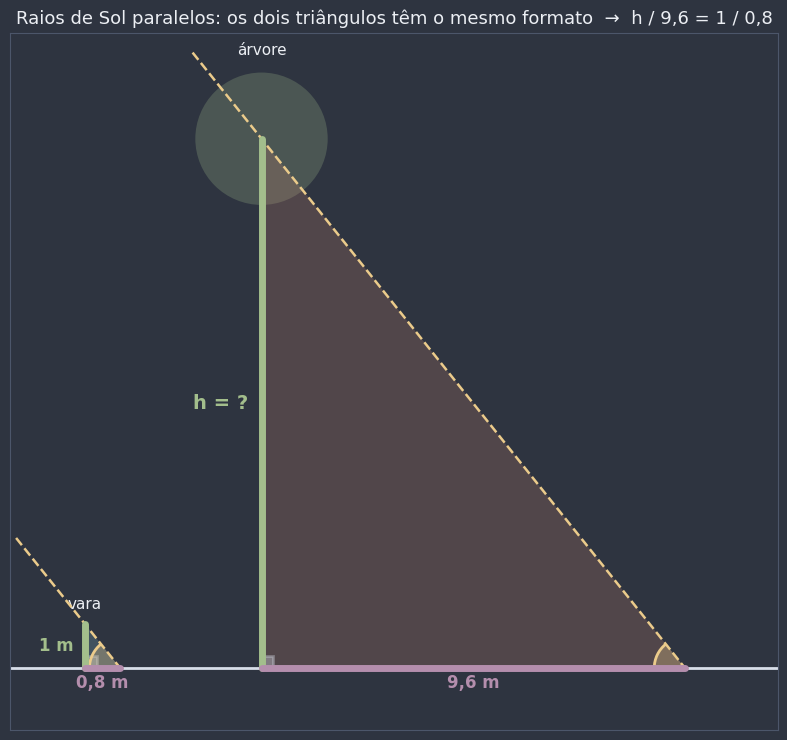

In [2]:
# Medidas feitas no MESMO instante, em metros
altura_vara, sombra_vara = 1.0, 0.8
sombra_arvore = 9.6

# Mesmo formato: a altura é "tantas vezes" a sombra, nos dois triângulos
altura_arvore = altura_vara * sombra_arvore / sombra_vara
print(f"razão altura/sombra da vara:  {altura_vara / sombra_vara:.3f}")
print(f"altura estimada da árvore:    {altura_arvore:.2f} m")

pe_vara, pe_arvore = np.array([0.0, 0.0]), np.array([4.0, 0.0])
topo_vara, topo_arvore = pe_vara + (0, altura_vara), pe_arvore + (0, altura_arvore)
ponta_vara, ponta_arvore = pe_vara + (sombra_vara, 0), pe_arvore + (sombra_arvore, 0)

fig, ax = plt.subplots(figsize=(12, 7.5))
fig.patch.set_facecolor(NORD_FUNDO)
preparar_eixo(ax, [(-1.5, -1.2), (15.5, 14.2)], margem=0.2)
ax.axhline(0, color=NORD_TEXTO_SEC, lw=2, zorder=2)  # o chão
ax.add_patch(Circle(topo_arvore, 1.5, facecolor=COR_DESTAQUE, alpha=0.25, edgecolor="none", zorder=1))  # a copa
for pe, topo, ponta, cor in ((pe_vara, topo_vara, ponta_vara, COR_T1), (pe_arvore, topo_arvore, ponta_arvore, COR_T2)):
    ax.add_patch(Polygon([pe, topo, ponta], closed=True, facecolor=cor, alpha=0.22, edgecolor="none", zorder=1))
    u_raio = (ponta - topo) / np.linalg.norm(ponta - topo)
    desenhar_segmento(ax, topo - 2.5 * u_raio, ponta, cor=COR_AVISO, largura=1.8, estilo="--")  # raio de Sol
    desenhar_segmento(ax, pe, topo, cor=COR_DESTAQUE, largura=5)  # altura
    desenhar_segmento(ax, pe, ponta, cor=COR_EXTRA, largura=5)  # sombra
    desenhar_arco(ax, pe, ponta, topo, raio=0.45, cor=NORD_TEXTO_SEC)  # ângulo reto
    desenhar_arco(ax, ponta, topo, pe, raio=0.7, cor=COR_AVISO)  # inclinação do Sol, a mesma nos dois
ax.text(-0.25, 0.5, "1 m", color=COR_DESTAQUE, fontsize=12, fontweight="bold", ha="right", va="center")
ax.text(0.4, -0.45, "0,8 m", color=COR_EXTRA, fontsize=12, fontweight="bold", ha="center")
ax.text(3.7, 6, "h = ?", color=COR_DESTAQUE, fontsize=14, fontweight="bold", ha="right", va="center")
ax.text(8.8, -0.45, "9,6 m", color=COR_EXTRA, fontsize=12, fontweight="bold", ha="center")
ax.text(0, 1.35, "vara", color=NORD_TEXTO, fontsize=11, ha="center")
ax.text(4, 13.9, "árvore", color=NORD_TEXTO, fontsize=11, ha="center")
ax.set_title("Raios de Sol paralelos: os dois triângulos têm o mesmo formato  →  h / 9,6 = 1 / 0,8",
             color=NORD_TEXTO, fontsize=13)
plt.tight_layout()
plt.show()

A árvore tem **12 m**. Repare na figura: os dois triângulos têm o ângulo reto no pé e o **mesmo ângulo** de inclinação do Sol na ponta da sombra (em amarelo). A razão "altura ÷ sombra" é a mesma nos dois, $\frac{1}{0{,}8} = \frac{h}{9{,}6}$. Por que dois ângulos iguais bastam para garantir isso? A resposta (o critério **AA**) chega na seção 3, e o problema volta, com mais situações, na seção 4.

### Um segundo mistério: o produto que não muda

Desenhe uma circunferência, marque um ponto $P$ **dentro** dela e trace várias cordas passando por $P$. Cada corda fica dividida por $P$ em **dois pedaços**. Meça os dois pedaços e **multiplique-os**.

**Antes de executar:** com cordas em direções bem diferentes (umas quase passando pelo centro, outras bem "de lado"), os produtos devem dar parecidos ou muito diferentes? A célula abaixo traça dez cordas por um mesmo ponto $P$ (a função `intersecoes_reta_circunferencia`, da primeira célula, encontra onde cada reta corta a circunferência; ela será explicada na seção 5).

direção da corda,1º pedaço,2º pedaço,corda inteira,produto dos pedaços
10°,8.123,1.693,9.815,13.7500
28°,8.352,1.646,9.999,13.7500
46°,8.037,1.711,9.748,13.7500
64°,7.229,1.902,9.131,13.7500
82°,6.071,2.265,8.336,13.7500
100°,4.786,2.873,7.659,13.7500
118°,3.625,3.793,7.418,13.7500
136°,2.756,4.988,7.745,13.7500
154°,2.193,6.270,8.463,13.7500
172°,1.862,7.386,9.247,13.7500


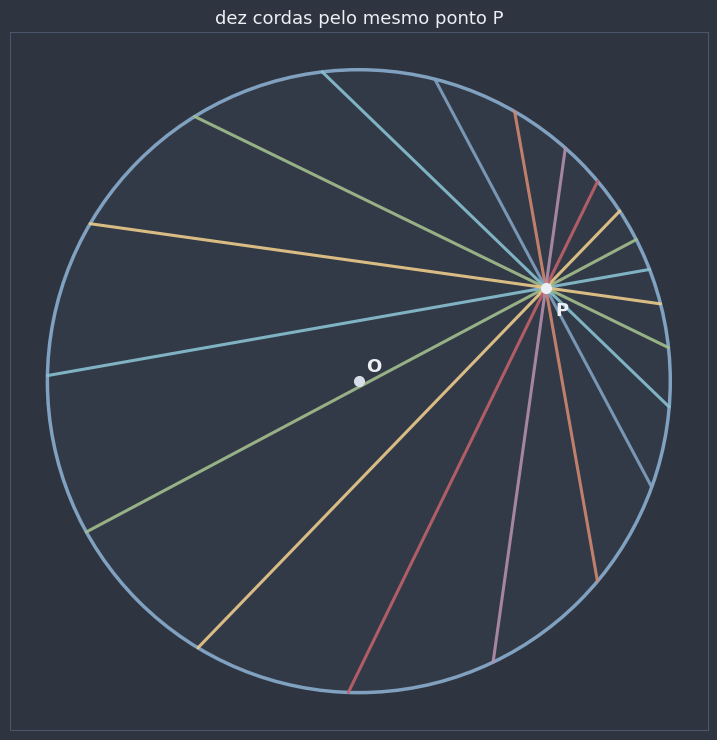

In [3]:
O_g, r_g = np.array([0.0, 0.0]), 5.0
P_g = np.array([3.0, 1.5])

linhas, cordas = [], []
for angulo in np.arange(10, 180, 18):  # dez direções diferentes
    X1, X2 = intersecoes_reta_circunferencia(O_g, r_g, P_g, angulo)
    pedaco_1, pedaco_2 = math.dist(P_g, X1), math.dist(P_g, X2)
    cordas.append((X1, X2))
    linhas.append({"direção da corda": f"{angulo:.0f}°", "1º pedaço": f"{pedaco_1:.3f}",
                   "2º pedaço": f"{pedaco_2:.3f}", "corda inteira": f"{pedaco_1 + pedaco_2:.3f}",
                   "produto dos pedaços": f"{pedaco_1 * pedaco_2:.4f}"})
display(pd.DataFrame(linhas).style.hide(axis="index"))

cores_cordas = [COR_PONTO, COR_DESTAQUE, COR_AVISO, COR_ALERTA, COR_EXTRA, "#D08770", COR_SECUNDARIA]
fig, ax = plt.subplots(figsize=(7.5, 7.5))
fig.patch.set_facecolor(NORD_FUNDO)
preparar_eixo(ax, [(-5, -5), (5, 5)], margem=0.6)
desenhar_circunferencia(ax, O_g, r_g, cor=COR_CIRCULO, preencher=True, opacidade=0.06)
for k, (X1, X2) in enumerate(cordas):
    desenhar_segmento(ax, X1, X2, cor=cores_cordas[k % len(cores_cordas)], largura=2.2, alpha=0.9)
desenhar_ponto(ax, O_g, "O", cor=NORD_TEXTO_SEC)
desenhar_ponto(ax, P_g, "P", cor=NORD_TEXTO, deslocamento=(0.15, -0.45))
ax.set_title("dez cordas pelo mesmo ponto P", color=NORD_TEXTO, fontsize=13)
plt.tight_layout()
plt.show()

As cordas medem de 7,4 a 10, e os pedaços mudam completamente (o menor tem 1,6 e o maior, 8,4)... mas o produto é **sempre 13,75**. Coincidência? Não: é um teorema, e a demonstração dele usa a mesma ideia da árvore, triângulos de mesmo formato. **Por que o produto não muda, se os pedaços mudam?** Guarde a pergunta: ela é respondida na seção 5.

### O fio condutor deste notebook

Três fios do módulo se encontram aqui: a **proporcionalidade** de [`0414a_teorema_de_tales.ipynb`](0414a_teorema_de_tales.ipynb), os **ângulos na circunferência** de [`0413a_angulos_na_circunferencia.ipynb`](0413a_angulos_na_circunferencia.ipynb) e as **tangentes e secantes** de [`0412a_circunferencia_e_circulo.ipynb`](0412a_circunferencia_e_circulo.ipynb). Cada seção usa a anterior, e a ordem **não pode ser invertida**:

| Seção | A ideia em uma frase | Demonstrada com... |
|---|---|---|
| 1. Triângulos semelhantes | mesmo formato: ângulos iguais e lados proporcionais, na razão $k$ | (definição) |
| 2. Teorema fundamental | uma paralela a um lado "recorta" um triângulo semelhante | Tales, paralelismo e paralelogramo |
| 3. Critérios AA, LAL, LLL | para garantir a semelhança, basta conferir **parte** das medidas | teorema fundamental + congruência |
| 4. Aplicações | alturas e larguras inacessíveis, escalas, maquetes | critérios |
| 5. Potência de ponto | o produto $PA \cdot PB$ não depende da reta que passa por $P$ | critério AA + ângulos inscritos |

Nenhuma demonstração deste notebook usa a semelhança antes de ela ser provada na seção 2: a cadeia é **Tales → teorema fundamental → critérios → potência de ponto**.

## 1. Triângulos semelhantes: definição e elementos

Em [`0405a_congruencia_de_triangulos.ipynb`](0405a_congruencia_de_triangulos.ipynb), dois triângulos **congruentes** tinham o mesmo formato **e** o mesmo tamanho: um coincidia com o outro depois de deslizar, girar ou refletir. Agora vamos permitir mais um movimento: **ampliar ou reduzir**, como no zoom de uma foto.

📌 **Definição formal (triângulos semelhantes):** os triângulos $ABC$ e $A'B'C'$ são **semelhantes**, e escrevemos $\triangle ABC \sim \triangle A'B'C'$, quando existe uma correspondência entre os vértices ($A \leftrightarrow A'$, $B \leftrightarrow B'$, $C \leftrightarrow C'$) tal que

1. os **ângulos correspondentes são congruentes**: $\hat{A} \equiv \hat{A'}$, $\hat{B} \equiv \hat{B'}$, $\hat{C} \equiv \hat{C'}$; e
2. os **lados correspondentes são proporcionais**:

$$\frac{A'B'}{AB} = \frac{B'C'}{BC} = \frac{C'A'}{CA} = k.$$

O número $k$ é a **razão de semelhança**: $k > 1$ é uma ampliação, $k < 1$ é uma redução e $k = 1$... é a **congruência**! A congruência de [`0405a_congruencia_de_triangulos.ipynb`](0405a_congruencia_de_triangulos.ipynb) é o **caso particular $k = 1$** da semelhança.

- **A ordem das letras indica a correspondência**, exatamente como na congruência: $\triangle ABC \sim \triangle DEF$ quer dizer $A \leftrightarrow D$, $B \leftrightarrow E$ e $C \leftrightarrow F$.
- **Elementos homólogos** são os que se correspondem: vértices homólogos, ângulos homólogos e **lados homólogos**, que são os lados **opostos a ângulos congruentes**. Nas figuras deste notebook, cada par de vértices homólogos tem uma cor (amarelo, verde, roxo), e o lado oposto a um vértice herda a cor dele.

**O que mais fica multiplicado por $k$?**

| Elemento | Razão entre os triângulos | Por quê |
|---|---|---|
| lados homólogos | $k$ | é a definição |
| **perímetros** | $k$ | $A'B' + B'C' + C'A' = k \cdot AB + k \cdot BC + k \cdot CA = k \cdot (AB + BC + CA)$ |
| **linhas homólogas** (alturas, medianas, bissetrizes, raios das circunferências inscrita e circunscrita) | $k$ | a justificativa usa os critérios da seção 3 (cada linha forma triângulos menores, também semelhantes); por enquanto, confira numericamente |
| **áreas** | $k^2$ | 📎 só um adiantamento: a área é "base × altura ÷ 2", e **as duas** ficam multiplicadas por $k$. A demonstração completa e as consequências vêm em 📌 Áreas de Superfícies Planas |

**No código:** a primeira célula definiu `lados(t)` (as medidas $a = BC$, $b = CA$, $c = AB$, na convenção de [`0404a_triangulos_conceito_elementos_e_classificacao.ipynb`](0404a_triangulos_conceito_elementos_e_classificacao.ipynb)), `angulos(t)` e `area_triangulo(t)`. A função `semelhantes(t1, t2)` faz o que a definição pede: experimenta as **6 correspondências** possíveis entre os vértices (com `permutations`, como em [`0405a_congruencia_de_triangulos.ipynb`](0405a_congruencia_de_triangulos.ipynb)) e devolve a primeira em que os ângulos correspondentes são iguais e os lados correspondentes são proporcionais, junto com $k$. A função `transformar` produz cópias de um triângulo ampliadas, giradas e refletidas. Uma das cópias tem os vértices listados **fora de ordem**, e a função descobre sozinha a correspondência certa.

In [4]:
def transformar(t, k: float = 1.0, rotacao: float = 0.0, refletir: bool = False, destino=(0.0, 0.0)):
    """Cópia do triângulo t ampliada (ou reduzida) pelo fator k, girada `rotacao` graus e, se pedido, refletida
    num espelho vertical, com o centro (a média dos vértices) levado até `destino`. São os movimentos de 0405a
    (deslizar, girar, refletir) mais a mudança de escala. A ordem dos vértices é mantida."""
    pontos = np.array(t, dtype=float)
    pontos = pontos - pontos.mean(axis=0)
    if refletir:
        pontos[:, 0] = -pontos[:, 0]
    giro = np.column_stack([direcao(rotacao), direcao(rotacao + 90)])  # matriz de rotação (módulo 03)
    pontos = k * pontos @ giro.T
    return [p + np.asarray(destino, dtype=float) for p in pontos]


def semelhantes(t1, t2):
    """Testa se os triângulos t1 e t2 são semelhantes. Experimenta as 6 correspondências possíveis entre os
    vértices (como em 0405a) e, na primeira que funcionar (ângulos correspondentes iguais E lados
    correspondentes proporcionais), devolve (ordem, k). A `ordem` é uma tupla como (2, 0, 1): o vértice 0 de t1
    corresponde ao vértice 2 de t2, o vértice 1 ao vértice 0, e o vértice 2 ao vértice 1. Devolve None se
    nenhuma correspondência funcionar."""
    lados_1, angulos_1 = lados(t1), angulos(t1)
    for ordem in permutations(range(3)):
        t2_reordenado = [t2[i] for i in ordem]
        razoes = [l2 / l1 for l1, l2 in zip(lados_1, lados(t2_reordenado))]
        lados_ok = all(iguais(razao, razoes[0]) for razao in razoes)
        angulos_ok = all(math.isclose(x, y, abs_tol=1e-6) for x, y in zip(angulos_1, angulos(t2_reordenado)))
        if lados_ok and angulos_ok:
            return ordem, razoes[0]
    return None


def descrever_correspondencia(ordem, nomes_1: str = "ABC", nomes_2=("A'", "B'", "C'")) -> str:
    """Texto como 'A↔F, B↔D, C↔E' a partir da `ordem` devolvida por `semelhantes`."""
    return ", ".join(f"{nomes_1[i]}↔{nomes_2[ordem[i]]}" for i in range(3))


t_original = [np.array([0.0, 0.0]), np.array([4.0, 0.0]), np.array([1.0, 3.0])]
girada = transformar(t_original, k=1.5, rotacao=70, destino=(18.5, 2.5))
deformada = transformar(t_original, k=1.2, rotacao=-15, destino=(9.5, 9.0))
deformada[2] = deformada[2] + np.array([0.9, 0.0])  # desloca um vértice: estraga o formato
copias = {
    "ampliada (k = 2)": (transformar(t_original, k=2, destino=(9.5, 1.5)), "DEF"),
    "girada 70° e com k = 1,5 (vértices fora de ordem)": ([girada[2], girada[0], girada[1]], "GHI"),
    "refletida (k = 0,5)": (transformar(t_original, k=0.5, refletir=True, destino=(2.0, 6.5)), "JKL"),
    "deformada (um vértice deslocado)": (deformada, "MNO"),
}


def altura_relativa_a_BC(t) -> float:
    """Altura do vértice t[0] até o lado oposto: 2 · área ÷ lado (vem de área = base × altura ÷ 2)."""
    return 2 * area_triangulo(t) / lados(t)[0]


def raio_inscrito(t) -> float:
    """Raio da circunferência inscrita (0410a), calculado como área ÷ semiperímetro."""
    return area_triangulo(t) / (sum(lados(t)) / 2)


linhas = []
for nome, (t, letras) in copias.items():
    resultado = semelhantes(t_original, t)
    linha = {"cópia": nome, "semelhante?": "sim" if resultado else "não",
             "perímetro'/perímetro": f"{sum(lados(t)) / sum(lados(t_original)):.4f}",
             "área'/área": f"{area_triangulo(t) / area_triangulo(t_original):.4f}"}
    if resultado:
        ordem, k = resultado
        t_reordenado = [t[i] for i in ordem]  # vértices na ordem que corresponde a A, B, C
        linha.update({"correspondência": descrever_correspondencia(ordem, "ABC", letras), "k": f"{k:.4f}",
                      "k²": f"{k**2:.4f}",
                      "altura'/altura": f"{altura_relativa_a_BC(t_reordenado) / altura_relativa_a_BC(t_original):.4f}",
                      "raio inscrito'/raio": f"{raio_inscrito(t_reordenado) / raio_inscrito(t_original):.4f}"})
    else:
        linha.update({"correspondência": "nenhuma serve", "k": "—", "k²": "—", "altura'/altura": "—",
                      "raio inscrito'/raio": "—"})
    linhas.append(linha)
colunas = ["cópia", "semelhante?", "correspondência", "k", "perímetro'/perímetro", "altura'/altura",
           "raio inscrito'/raio", "área'/área", "k²"]
display(pd.DataFrame(linhas)[colunas].style.hide(axis="index"))

cópia,semelhante?,correspondência,k,perímetro'/perímetro,altura'/altura,raio inscrito'/raio,área'/área,k²
ampliada (k = 2),sim,"A↔D, B↔E, C↔F",2.0000,2.0000,2.0000,2.0000,4.0000,4.0000
"girada 70° e com k = 1,5 (vértices fora de ordem)",sim,"A↔H, B↔I, C↔G",1.5000,1.5000,1.5000,1.5000,2.2500,2.2500
"refletida (k = 0,5)",sim,"A↔J, B↔K, C↔L",0.5000,0.5000,0.5000,0.5000,0.2500,0.2500
deformada (um vértice deslocado),não,nenhuma serve,—,1.2154,—,—,1.5332,—


Nas três cópias semelhantes, as colunas "perímetro", "altura" e "raio inscrito" repetem exatamente o valor de $k$, e a coluna "área" repete $k^2$. Na cópia girada, os vértices foram listados na ordem $G, H, I$ mas a correspondência encontrada foi $A \leftrightarrow H$, $B \leftrightarrow I$, $C \leftrightarrow G$: o certo é escrever $\triangle ABC \sim \triangle HIG$. Na cópia deformada, nenhuma das 6 correspondências funciona.

A representação gráfica: cada vértice tem a cor do seu homólogo no triângulo original (e o lado oposto a ele também). Repare que, na cópia refletida, a ordem amarelo → verde → roxo dá a volta no sentido **contrário**: a reflexão inverte o sentido, mas não estraga a semelhança.

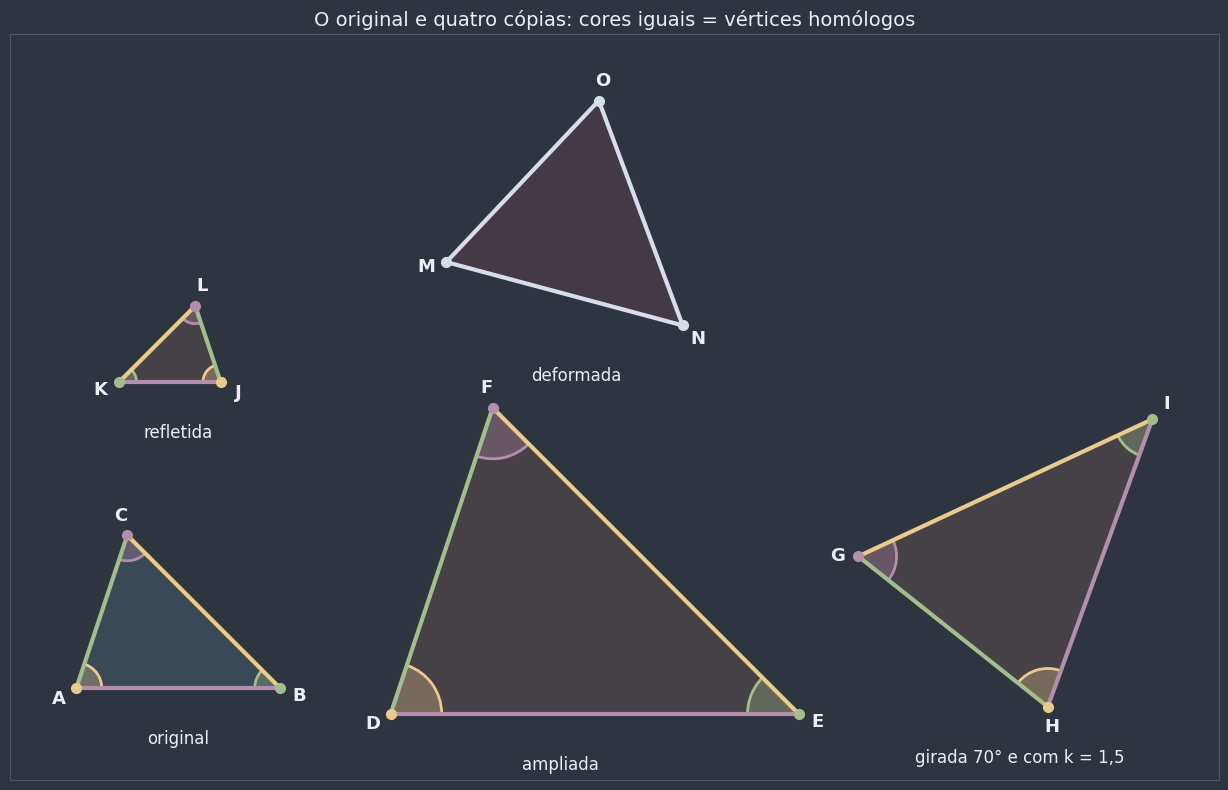

In [5]:
fig, ax = plt.subplots(figsize=(15, 8))
fig.patch.set_facecolor(NORD_FUNDO)
todos = list(t_original) + [p for t, _ in copias.values() for p in t]
preparar_eixo(ax, todos, margem=1.3)
desenhar_triangulo(ax, t_original, "ABC", cor_preenchimento=COR_T1, raio_angulo=0.5)
ax.text(2, -1.1, "original", color=NORD_TEXTO, fontsize=12, ha="center")
for nome, (t, letras) in copias.items():
    resultado = semelhantes(t_original, t)
    centro = sum(np.asarray(p) for p in t) / 3
    base = min(p[1] for p in t)
    if resultado:
        ordem, k = resultado
        cores = [None] * 3
        for i in range(3):
            cores[ordem[i]] = CORES_VERTICES[i]  # o vértice ordem[i] da cópia é o homólogo do vértice i
        desenhar_triangulo(ax, t, letras, cores=cores, cor_preenchimento=COR_T2, raio_angulo=0.5 * max(k, 0.7))
    else:
        desenhar_triangulo(ax, t, letras, cores=[NORD_TEXTO_SEC] * 3, cor_preenchimento=COR_ALERTA,
                           marcar_angulos=False)
    ax.text(centro[0], base - 1.1, nome.split(" (")[0], color=NORD_TEXTO, fontsize=12, ha="center")
ax.set_title("O original e quatro cópias: cores iguais = vértices homólogos", color=NORD_TEXTO, fontsize=14)
plt.tight_layout()
plt.show()

🕹️ **Widget interativo:** o slider `k` amplia ou reduz a cópia, `rotação` gira a cópia e a caixa `refletir` a espelha. O painel confere a definição em tempo real: as três razões entre lados homólogos (sempre $k$), os três pares de ângulos (sempre iguais), a razão dos perímetros ($k$) e a das áreas ($k^2$). Tente: com $k = 2$, a área fica **quatro** vezes maior; com $k = 3$, **nove** vezes. E com $k = 1$?

In [ ]:
def explorar_semelhanca(k: float, rotacao: float, refletir: bool) -> None:
    t1 = [np.array([0.0, 0.0]), np.array([4.0, 0.0]), np.array([1.0, 3.0])]
    t2 = transformar(t1, k=k, rotacao=rotacao, refletir=refletir, destino=(11.5, 2.0))
    lados_1, lados_2 = lados(t1), lados(t2)
    angulos_1, angulos_2 = angulos(t1), angulos(t2)

    fig, (ax, ax_lista) = plt.subplots(1, 2, figsize=(15, 6.4), gridspec_kw={"width_ratios": [1.6, 1]})
    fig.patch.set_facecolor(NORD_FUNDO)
    preparar_eixo(ax, [(-1, -5), (18.5, 8.7)], margem=0.2)
    desenhar_triangulo(ax, t1, "ABC", cor_preenchimento=COR_T1)
    desenhar_triangulo(ax, t2, ("A'", "B'", "C'"), cor_preenchimento=COR_T2, raio_angulo=0.45 * max(k, 0.7))
    tipo = "congruência (k = 1)" if math.isclose(k, 1) else ("ampliação" if k > 1 else "redução")
    ax.set_title(f"△ABC ~ △A'B'C'   ({tipo})", color=NORD_TEXTO, fontsize=13)

    nomes_lados = ("B'C'/BC", "C'A'/CA", "A'B'/AB")
    itens = [(f"{nome} = {l2:.3f}/{l1:.3f} = {l2 / l1:.4f}", iguais(l2 / l1, k))
             for nome, l1, l2 in zip(nomes_lados, lados_1, lados_2)]
    itens += [(f"{v}: {a1:.2f}° e {a2:.2f}°", math.isclose(a1, a2, abs_tol=1e-6))
              for v, a1, a2 in zip(("Â e Â'", "B̂ e B̂'", "Ĉ e Ĉ'"), angulos_1, angulos_2)]
    itens.append((f"perímetros: {sum(lados_2):.3f}/{sum(lados_1):.3f} = {sum(lados_2) / sum(lados_1):.4f} = k",
                  iguais(sum(lados_2) / sum(lados_1), k)))
    razao_areas = area_triangulo(t2) / area_triangulo(t1)
    itens.append((f"áreas: {razao_areas:.4f} = k² = {k**2:.4f}", iguais(razao_areas, k**2)))
    escrever_checklist(ax_lista, itens, f"Conferindo a definição (k = {k:g})")
    plt.tight_layout()
    plt.show()


widgets.interact(
    explorar_semelhanca,
    k=widgets.FloatSlider(value=1.5, min=0.3, max=2.5, step=0.1, description="k:"),
    rotacao=widgets.FloatSlider(value=30, min=-180, max=180, step=5, description="rotação:"),
    refletir=widgets.Checkbox(value=False, description="refletir"),
);

interactive(children=(FloatSlider(value=1.5, description='k:', max=2.5, min=0.3), FloatSlider(value=30.0, desc…

⚠️ **Erro comum: dividir os lados "na ordem em que aparecem".** A semelhança é uma afirmação sobre uma **correspondência**: os lados que se dividem são os **homólogos** (opostos a ângulos congruentes), não os que aparecem na mesma posição no texto. Um exemplo: o triângulo $ABC$ tem $AB = 4$, $BC = 6$, $CA = 8$, e o triângulo $DEF$ tem $DE = 9$, $EF = 12$, $FD = 6$. Quem escreve "$\triangle ABC \sim \triangle DEF$" e divide $\frac{DE}{AB}$, $\frac{EF}{BC}$, $\frac{FD}{CA}$ encontra três razões diferentes e conclui (errado) que eles não são semelhantes. A célula abaixo confere as duas leituras.

In [7]:
t_ABC = triangulo_por_lados(6, 8, 4)  # BC = 6, CA = 8, AB = 4
t_DEF = triangulo_por_lados(12, 6, 9)  # EF = 12, FD = 6, DE = 9

print("Leitura errada, 'ABC ~ DEF' (A↔D, B↔E, C↔F):")
for par, l1, l2 in zip(("EF/BC", "FD/CA", "DE/AB"), lados(t_ABC), lados(t_DEF)):
    print(f"   {par} = {l2:g}/{l1:g} = {l2 / l1:.4f}")
for v, a1, a2 in zip(("Â e D̂", "B̂ e Ê", "Ĉ e F̂"), angulos(t_ABC), angulos(t_DEF)):
    print(f"   {v}: {a1:.2f}° e {a2:.2f}°")

ordem, k = semelhantes(t_ABC, t_DEF)
print(f"\nCorrespondência encontrada por semelhantes: {descrever_correspondencia(ordem, 'ABC', 'DEF')}   (k = {k:g})")
t_reordenado = [t_DEF[i] for i in ordem]
for par, l1, l2 in zip(("DE/BC", "EF/CA", "FD/AB"), lados(t_ABC), lados(t_reordenado)):
    print(f"   {par} = {l2:g}/{l1:g} = {l2 / l1:.4f}")

Leitura errada, 'ABC ~ DEF' (A↔D, B↔E, C↔F):
   EF/BC = 12/6 = 2.0000
   FD/CA = 6/8 = 0.7500
   DE/AB = 9/4 = 2.2500
   Â e D̂: 46.57° e 104.48°
   B̂ e Ê: 104.48° e 28.96°
   Ĉ e F̂: 28.96° e 46.57°

Correspondência encontrada por semelhantes: A↔F, B↔D, C↔E   (k = 1.5)
   DE/BC = 9/6 = 1.5000
   EF/CA = 12/8 = 1.5000
   FD/AB = 6/4 = 1.5000


Os triângulos **são** semelhantes, mas a correspondência certa é $A \leftrightarrow F$, $B \leftrightarrow D$, $C \leftrightarrow E$: escreve-se $\triangle ABC \sim \triangle FDE$, com $k = 1{,}5$. Regra prática: em triângulos semelhantes, o **menor** lado corresponde ao **menor**, o médio ao médio e o maior ao maior (porque ao maior ângulo opõe-se o maior lado, [`0404a_triangulos_conceito_elementos_e_classificacao.ipynb`](0404a_triangulos_conceito_elementos_e_classificacao.ipynb)). Os ângulos confirmam: na leitura errada, $\hat{A}$ e $\hat{D}$ nem são iguais.

💡 **Dica:** "semelhante", na geometria, **não** quer dizer "parecido": exige proporção **exata**. Um quadrado e um retângulo não quadrado nunca são semelhantes, embora "pareçam" (os ângulos são todos iguais, mas a razão entre lados vizinhos é $1$ num e diferente de $1$ no outro). Já **dois triângulos equiláteros quaisquer** são sempre semelhantes.

🎯 **Aplicação prática — escalas em mapas, plantas e maquetes:** a escala de uma planta é uma razão de semelhança. Numa planta na escala 1 : 100, cada medida real é $k = 100$ vezes a do papel, e **as áreas são $k^2 = 10\,000$ vezes maiores**. Isso pesa no bolso: ampliar uma embalagem em 20% em cada dimensão gasta $1{,}2^2 = 1{,}44$ vezes o papelão das faces, e ampliar um cômodo para o dobro das medidas quadruplica a tinta das paredes e do piso.

📖 **Leitura complementar:** [Semelhança de triângulos](https://pt.wikipedia.org/wiki/Semelhan%C3%A7a_de_tri%C3%A2ngulos) e [Semelhança (geometria)](https://pt.wikipedia.org/wiki/Semelhan%C3%A7a_(geometria)), na Wikipédia.

**Pergunta de checagem:** dois triângulos têm lados de 3, 4, 5 e de 9, 12, 15. São semelhantes? Qual a razão de semelhança? E a razão entre as áreas?

**Pergunta de checagem:** se $\triangle ABC \sim \triangle PQR$, qual lado de $PQR$ é homólogo a $\overline{CA}$? E qual ângulo é congruente a $\hat{B}$?

## 2. O teorema fundamental da semelhança

A definição pede **seis** conferências (três ângulos e três razões). O primeiro resultado mostra uma situação em que todas valem automaticamente, e ele é o tijolo com que todo o resto deste notebook é construído.

📌 **Teorema fundamental da semelhança:** se uma reta **paralela a um lado** de um triângulo corta os outros dois lados em pontos distintos, ela determina um triângulo **semelhante** ao primeiro. Em símbolos: se $\overline{DE} \parallel \overline{BC}$, com $D$ em $\overline{AB}$ e $E$ em $\overline{AC}$, então

$$\triangle ADE \sim \triangle ABC \qquad \text{e} \qquad \frac{AD}{AB} = \frac{AE}{AC} = \frac{DE}{BC}.$$

### Demonstração (o ponto de honra do notebook)

Em [`0414a_teorema_de_tales.ipynb`](0414a_teorema_de_tales.ipynb), o ⚠️ "o que Tales diz e o que ele não diz" avisou: Tales dá as razões **sobre os lados** $\overline{AB}$ e $\overline{AC}$, mas **não** dá $\frac{DE}{BC}$, porque $\overline{DE}$ e $\overline{BC}$ estão **sobre as paralelas**. É essa lacuna que a demonstração fecha. Para o terceiro par de lados, trace por $E$ a paralela a $\overline{AB}$, que corta $\overline{BC}$ no ponto $F$.

| Passo | Afirmação | Justificativa |
|---|---|---|
| 1 | $\hat{A}$ é comum aos dois triângulos | é o mesmo ângulo |
| 2 | $A\hat{D}E \equiv A\hat{B}C$ | ângulos **correspondentes**: $\overleftrightarrow{DE} \parallel \overleftrightarrow{BC}$, com a transversal $\overleftrightarrow{AB}$ ([`0406a_paralelismo.ipynb`](0406a_paralelismo.ipynb)) |
| 3 | $A\hat{E}D \equiv A\hat{C}B$ | ângulos **correspondentes**, agora com a transversal $\overleftrightarrow{AC}$ ([`0406a_paralelismo.ipynb`](0406a_paralelismo.ipynb)) |
| 4 | $\dfrac{AD}{AB} = \dfrac{AE}{AC}$ | **Tales no triângulo**, segunda forma ([`0414a_teorema_de_tales.ipynb`](0414a_teorema_de_tales.ipynb)) |
| 5 | $DBFE$ é um paralelogramo | $\overline{DE} \parallel \overline{BF}$ (hipótese) e $\overline{EF} \parallel \overline{DB}$ (construção): dois pares de lados opostos paralelos ([`0409a_paralelogramos_e_casos_particulares.ipynb`](0409a_paralelogramos_e_casos_particulares.ipynb)) |
| 6 | $DE = BF$ | lados opostos de um paralelogramo são congruentes ([`0409a_paralelogramos_e_casos_particulares.ipynb`](0409a_paralelogramos_e_casos_particulares.ipynb)) |
| 7 | $\dfrac{CF}{CB} = \dfrac{CE}{CA}$ | **Tales no triângulo** $CAB$, com $\overline{EF} \parallel \overline{AB}$ ([`0414a_teorema_de_tales.ipynb`](0414a_teorema_de_tales.ipynb)) |
| 8 | $\dfrac{BF}{BC} = \dfrac{AE}{AC}$ | $\dfrac{BF}{BC} = \dfrac{BC - CF}{BC} = 1 - \dfrac{CF}{CB} = 1 - \dfrac{CE}{CA} = \dfrac{CA - CE}{CA} = \dfrac{AE}{AC}$ (passo 7) |
| 9 | $\dfrac{DE}{BC} = \dfrac{AE}{AC} = \dfrac{AD}{AB}$ | passos 6, 8 e 4 |
| 10 | $\triangle ADE \sim \triangle ABC$ | ângulos correspondentes congruentes (passos 1 a 3) e lados correspondentes proporcionais (passo 9): é a definição da seção 1 ∎ |

Repare que a demonstração usa **só** o que o curso já tinha: paralelismo, paralelogramo e Tales. Ela **não** usa semelhança para provar semelhança. A razão de semelhança é $k = \frac{AD}{AB}$, e a correspondência é $A \leftrightarrow A$, $D \leftrightarrow B$, $E \leftrightarrow C$.

📎 **Conexão:** a **base média do triângulo** ([`0408a_quadrilateros_definicao_elementos_e_trapezios.ipynb`](0408a_quadrilateros_definicao_elementos_e_trapezios.ipynb)) é o caso $k = \frac{1}{2}$, com $D$ e $E$ nos pontos médios. O teorema fundamental dá $DE = \frac{BC}{2}$ na hora, e ainda mostra que o triângulo $ADE$ tem $\frac{1}{4}$ da área de $ABC$.

**No código:** com um parâmetro $t$ entre 0 e 1, o ponto $D = A + t(B - A)$ anda a fração $t$ do caminho de $A$ até $B$, e $E = A + t(C - A)$ anda a mesma fração de $A$ até $C$. A tabela confere, de forma independente, que $\overline{DE} \parallel \overline{BC}$ (pelo produto vetorial, `sao_paralelos`), que as **três** razões valem $t$, que os ângulos correspondentes são iguais e que $DE = BF$ (passo 6).

In [8]:
A, B, C = np.array([2.0, 6.0]), np.array([0.0, 0.0]), np.array([9.0, 0.0])
linhas = []
for t in [0.2, 0.25, 0.4, 0.5, 0.75, 0.9]:
    D, E = A + t * (B - A), A + t * (C - A)
    F = cruzamento_das_retas(E, E + (B - A), B, C)  # a paralela a AB por E corta BC em F
    linhas.append({"t": f"{t:g}", "DE ∥ BC?": "sim" if sao_paralelos(D, E, B, C) else "não",
                   "AD/AB": f"{math.dist(A, D) / math.dist(A, B):.4f}",
                   "AE/AC": f"{math.dist(A, E) / math.dist(A, C):.4f}",
                   "DE/BC": f"{math.dist(D, E) / math.dist(B, C):.4f}",
                   "ADE e ABC": f"{medir_angulo(D, A, E):.2f}° e {medir_angulo(B, A, C):.2f}°",
                   "AED e ACB": f"{medir_angulo(E, A, D):.2f}° e {medir_angulo(C, A, B):.2f}°",
                   "DE": f"{math.dist(D, E):.4f}", "BF": f"{math.dist(B, F):.4f}"})
display(pd.DataFrame(linhas).style.hide(axis="index"))

t,DE ∥ BC?,AD/AB,AE/AC,DE/BC,ADE e ABC,AED e ACB,DE,BF
0.2,sim,0.2000,0.2000,0.2000,71.57° e 71.57°,40.60° e 40.60°,1.8000,1.8000
0.25,sim,0.2500,0.2500,0.2500,71.57° e 71.57°,40.60° e 40.60°,2.2500,2.2500
0.4,sim,0.4000,0.4000,0.4000,71.57° e 71.57°,40.60° e 40.60°,3.6000,3.6000
0.5,sim,0.5000,0.5000,0.5000,71.57° e 71.57°,40.60° e 40.60°,4.5000,4.5000
0.75,sim,0.7500,0.7500,0.7500,71.57° e 71.57°,40.60° e 40.60°,6.7500,6.7500
0.9,sim,0.9000,0.9000,0.9000,71.57° e 71.57°,40.60° e 40.60°,8.1000,8.1000


A coluna dos ângulos precisa de atenção à notação: "ADE e ABC" compara o ângulo de vértice $D$ com o de vértice $B$ (os dois primeiros valores são medidos com `medir_angulo(D, A, E)` e `medir_angulo(B, A, C)`). As três razões coincidem com $t$ em todas as linhas, e $DE = BF$ sempre.

A representação gráfica. À esquerda, a demonstração: o paralelogramo $DBFE$ (azul) transporta $\overline{DE}$ para cima de $\overline{BC}$, e $\overline{DE}$ e $\overline{BC}$ têm a mesma cor (amarelo) porque são homólogos, os dois opostos ao ângulo $\hat{A}$. Os ângulos em $D$ e $B$ (verdes) e em $E$ e $C$ (roxos) são correspondentes. À direita, a base média ($t = \frac{1}{2}$).

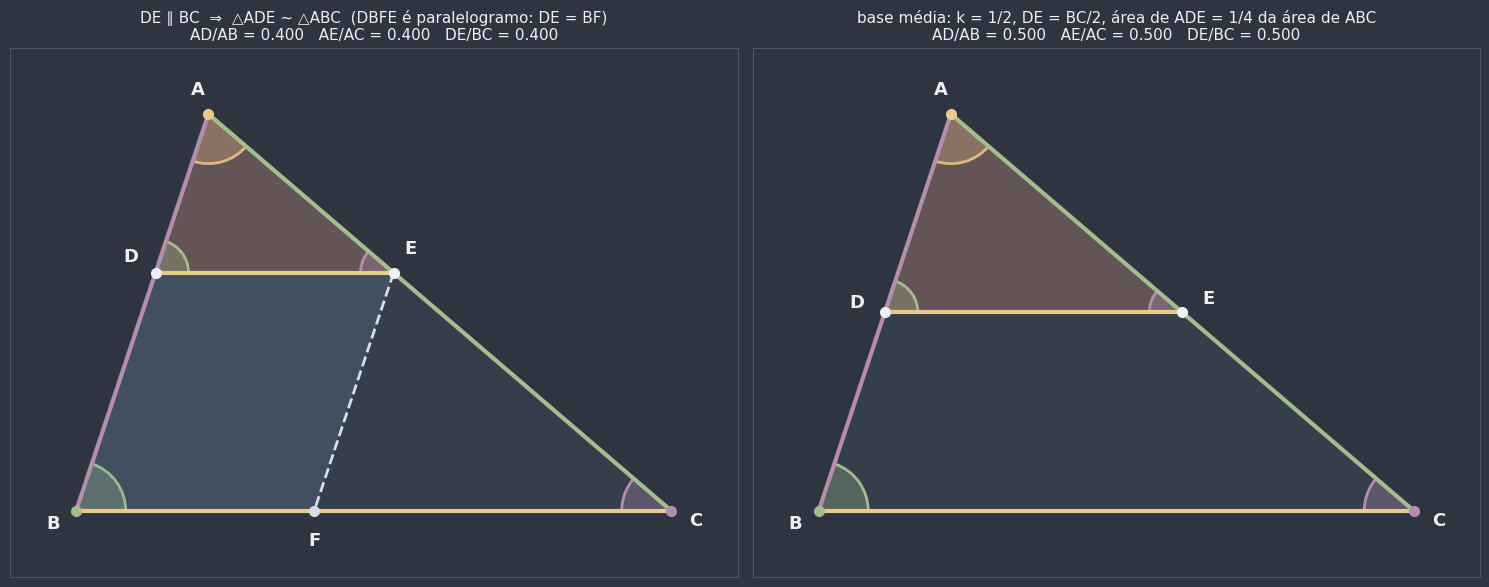

In [9]:
def desenhar_fundamental(ax, A, B, C, t: float, mostrar_F: bool = True) -> None:
    """Desenha o triângulo ABC, a paralela DE (D = A + t(B − A), E = A + t(C − A)) e, se pedido, o
    paralelogramo DBFE da demonstração."""
    D, E = A + t * (B - A), A + t * (C - A)
    F = cruzamento_das_retas(E, E + (B - A), B, C)
    desenhar_triangulo(ax, [A, B, C], "ABC", cor_preenchimento=COR_T1, opacidade=0.08, raio_angulo=0.75)
    ax.add_patch(Polygon([A, D, E], closed=True, facecolor=COR_T2, alpha=0.3, edgecolor="none", zorder=1))
    if mostrar_F:
        ax.add_patch(Polygon([D, B, F, E], closed=True, facecolor=COR_SECUNDARIA, alpha=0.18, edgecolor="none"))
        desenhar_segmento(ax, E, F, cor=NORD_TEXTO_SEC, largura=2, estilo="--")
        desenhar_ponto(ax, F, cor=NORD_TEXTO_SEC)
        rotular_fora(ax, F, "F", F + (0, 1), distancia=0.45, tamanho=13)
    desenhar_segmento(ax, D, E, cor=CORES_VERTICES[0], largura=3, zorder=5)  # DE: homólogo de BC
    desenhar_arco(ax, D, A, E, raio=0.5, cor=CORES_VERTICES[1])
    desenhar_arco(ax, E, A, D, raio=0.5, cor=CORES_VERTICES[2])
    for X, nome in ((D, "D"), (E, "E")):
        desenhar_ponto(ax, X, cor=NORD_TEXTO)
        rotular_fora(ax, X, nome, (A + B + C) / 3, distancia=0.45, tamanho=13)


fig, eixos = plt.subplots(1, 2, figsize=(15, 6.6))
fig.patch.set_facecolor(NORD_FUNDO)
for ax, t, titulo in ((eixos[0], 0.4, "DE ∥ BC  ⇒  △ADE ~ △ABC  (DBFE é paralelogramo: DE = BF)"),
                      (eixos[1], 0.5, "base média: k = 1/2, DE = BC/2, área de ADE = 1/4 da área de ABC")):
    preparar_eixo(ax, [A, B, C], margem=1.0)
    desenhar_fundamental(ax, A, B, C, t, mostrar_F=(t != 0.5))
    D, E = A + t * (B - A), A + t * (C - A)
    ax.set_title(f"{titulo}\nAD/AB = {math.dist(A, D) / math.dist(A, B):.3f}   "
                 f"AE/AC = {math.dist(A, E) / math.dist(A, C):.3f}   DE/BC = {math.dist(D, E) / math.dist(B, C):.3f}",
                 color=NORD_TEXTO, fontsize=11)
plt.tight_layout()
plt.show()

🕹️ **Widget interativo:** o slider `t` desloca a paralela. O triângulo $ADE$ (laranja) cresce de quase nada até quase o triângulo inteiro, e o painel mostra as três razões (sempre iguais a $t$), os ângulos correspondentes, a igualdade $DE = BF$ do paralelogramo e a razão entre as áreas ($t^2$). A caixa `paralelogramo` mostra ou esconde a construção auxiliar da demonstração.

In [ ]:
def explorar_fundamental(t: float, paralelogramo: bool) -> None:
    A_w, B_w, C_w = np.array([2.0, 6.0]), np.array([0.0, 0.0]), np.array([9.0, 0.0])
    D_w, E_w = A_w + t * (B_w - A_w), A_w + t * (C_w - A_w)
    F_w = cruzamento_das_retas(E_w, E_w + (B_w - A_w), B_w, C_w)
    razoes = [math.dist(A_w, D_w) / math.dist(A_w, B_w), math.dist(A_w, E_w) / math.dist(A_w, C_w),
              math.dist(D_w, E_w) / math.dist(B_w, C_w)]

    fig, (ax, ax_lista) = plt.subplots(1, 2, figsize=(14, 6.2), gridspec_kw={"width_ratios": [1.25, 1]})
    fig.patch.set_facecolor(NORD_FUNDO)
    preparar_eixo(ax, [A_w, B_w, C_w], margem=1.0)
    desenhar_fundamental(ax, A_w, B_w, C_w, t, mostrar_F=paralelogramo)
    ax.set_title(f"t = {t:.2f}:  △ADE ~ △ABC com k = {t:.2f}", color=NORD_TEXTO, fontsize=13)
    itens = [
        (f"DE ∥ BC (produto vetorial = {produto_vetorial(E_w - D_w, C_w - B_w):+.1e})",
         sao_paralelos(D_w, E_w, B_w, C_w)),
        (f"AD/AB = {razoes[0]:.4f}", iguais(razoes[0], t)),
        (f"AE/AC = {razoes[1]:.4f}", iguais(razoes[1], t)),
        (f"DE/BC = {razoes[2]:.4f}  (o par que Tales não dava)", iguais(razoes[2], t)),
        (f"ângulo em D = {medir_angulo(D_w, A_w, E_w):.2f}° = ângulo em B = {medir_angulo(B_w, A_w, C_w):.2f}°",
         math.isclose(medir_angulo(D_w, A_w, E_w), medir_angulo(B_w, A_w, C_w), abs_tol=1e-6)),
        (f"DE = {math.dist(D_w, E_w):.3f} = BF = {math.dist(B_w, F_w):.3f}  (paralelogramo DBFE)",
         iguais(math.dist(D_w, E_w), math.dist(B_w, F_w))),
        (f"área(ADE)/área(ABC) = {area_triangulo([A_w, D_w, E_w]) / area_triangulo([A_w, B_w, C_w]):.4f} = t²",
         iguais(area_triangulo([A_w, D_w, E_w]) / area_triangulo([A_w, B_w, C_w]), t**2)),
    ]
    escrever_checklist(ax_lista, itens, "Teorema fundamental")
    plt.tight_layout()
    plt.show()


widgets.interact(
    explorar_fundamental,
    t=widgets.FloatSlider(value=0.4, min=0.05, max=0.95, step=0.05, description="t:"),
    paralelogramo=widgets.Checkbox(value=True, description="paralelogramo"),
);

interactive(children=(FloatSlider(value=0.4, description='t:', max=0.95, min=0.05, step=0.05), Checkbox(value=…

💡 **Dica:** em linguagem de coordenadas, $E - D = t(C - A) - t(B - A) = t\,(C - B)$. O vetor $\overrightarrow{DE}$ é o vetor $\overrightarrow{BC}$ multiplicado por $t$: tem a mesma direção (paralelo) e $t$ vezes o tamanho. É o teorema fundamental inteiro numa linha, e você vai reencontrar essa ideia em 📌 Geometria Analítica.

⚠️ **Erro comum:** usar a proporção $\frac{AD}{DB}$ no lugar de $\frac{AD}{AB}$ para calcular $\overline{DE}$. O segmento paralelo se compara com o lado **inteiro**: $\frac{DE}{BC} = \frac{AD}{AB}$, e **não** $\frac{AD}{DB}$. (A razão $\frac{AD}{DB} = \frac{AE}{EC}$ vale, mas é Tales, e não envolve $\overline{DE}$.)

**Pergunta de checagem:** num triângulo $ABC$, $\overline{DE} \parallel \overline{BC}$, com $AD = 3$, $DB = 6$ e $BC = 12$. Quanto mede $\overline{DE}$?

**Pergunta de checagem:** na demonstração, por que foi preciso construir o ponto $F$? Por que não bastava aplicar Tales ao triângulo $ABC$ com a paralela $\overline{DE}$?

## 3. Critérios (casos) de semelhança: AA, LAL, LLL

Na congruência ([`0405a_congruencia_de_triangulos.ipynb`](0405a_congruencia_de_triangulos.ipynb)), não era preciso conferir as seis medidas: os **casos** LAL, ALA, LLL e LAAo bastavam. Com a semelhança acontece o mesmo.

📌 **Critérios de semelhança** (com a correspondência $A \leftrightarrow A'$, $B \leftrightarrow B'$, $C \leftrightarrow C'$):

| Critério | O que precisa ser verificado | O que se ganha de graça |
|---|---|---|
| **AA** (ângulo–ângulo) | $\hat{A} \equiv \hat{A'}$ e $\hat{B} \equiv \hat{B'}$ | $\hat{C} \equiv \hat{C'}$ (soma 180°, [`0404a_triangulos_conceito_elementos_e_classificacao.ipynb`](0404a_triangulos_conceito_elementos_e_classificacao.ipynb)) e os três lados proporcionais |
| **LAL** (lado–ângulo–lado) | $\dfrac{A'B'}{AB} = \dfrac{A'C'}{AC}$ e $\hat{A} \equiv \hat{A'}$, o ângulo **entre** esses lados | o terceiro lado na mesma razão e os outros dois ângulos |
| **LLL** (lado–lado–lado) | $\dfrac{A'B'}{AB} = \dfrac{B'C'}{BC} = \dfrac{C'A'}{CA}$ | os três ângulos congruentes |

🕵️ **Contraste com a congruência:** em [`0405a_congruencia_de_triangulos.ipynb`](0405a_congruencia_de_triangulos.ipynb), o "falso caso" **AAA** mostrava que três ângulos iguais **não** garantem congruência: os triângulos podem ter tamanhos diferentes. Agora a mesma observação vira um teorema: **AA basta para a semelhança**. É exatamente a diferença entre "mesmo formato" (semelhança) e "mesmo formato **e** mesmo tamanho" (congruência). Os ângulos controlam o formato; para controlar o tamanho, é preciso pelo menos um lado.

### Demonstrações: o método da "sobreposição"

Os três critérios se demonstram com o **mesmo esquema**. Suponha, sem perda de generalidade, que $A'B'C'$ é o **menor** (se for o maior, troque os papéis; se for do mesmo tamanho, é congruência pura). A ideia é **encaixar uma cópia** de $A'B'C'$ dentro de $ABC$, com o vértice $A'$ sobre $A$: marque em $\overline{AB}$ o ponto $D$ com $AD = A'B'$ e em $\overline{AC}$ o ponto $E$ com $AE = A'C'$. Depois, (1) mostre que $ADE$ é uma cópia **congruente** de $A'B'C'$ e (2) que $\overline{DE} \parallel \overline{BC}$, para usar o teorema fundamental.

**Critério LAL, com todos os detalhes.** Hipótese: $\hat{A} \equiv \hat{A'}$ e $\frac{A'B'}{AB} = \frac{A'C'}{AC} = k < 1$.

| Passo | Afirmação | Justificativa |
|---|---|---|
| 1 | $D$ em $\overline{AB}$ com $AD = A'B'$ e $E$ em $\overline{AC}$ com $AE = A'C'$ | construção (com o compasso); cabe, porque $A'B' < AB$ e $A'C' < AC$ |
| 2 | $\triangle ADE \equiv \triangle A'B'C'$ | caso **LAL** de congruência: $AD = A'B'$, $\hat{A} \equiv \hat{A'}$ e $AE = A'C'$ ([`0405a_congruencia_de_triangulos.ipynb`](0405a_congruencia_de_triangulos.ipynb)) |
| 3 | $\dfrac{AD}{AB} = \dfrac{AE}{AC} = k$ | passo 1 e a hipótese |
| 4 | $\overline{DE} \parallel \overline{BC}$ | **recíproca de Tales** no triângulo ([`0414a_teorema_de_tales.ipynb`](0414a_teorema_de_tales.ipynb)); do passo 3, pela propriedade da soma, sai $\frac{AD}{DB} = \frac{AE}{EC}$ |
| 5 | $\triangle ADE \sim \triangle ABC$ | **teorema fundamental** (seção 2) |
| 6 | $\triangle A'B'C' \sim \triangle ABC$ | passos 2 e 5: $A'B'C'$ é uma cópia exata de $ADE$, que é semelhante a $ABC$ ∎ |

**Critério AA, em esboço.** Hipótese: $\hat{A} \equiv \hat{A'}$ e $\hat{B} \equiv \hat{B'}$, com $A'B' < AB$. Marque $D$ em $\overline{AB}$ com $AD = A'B'$ e trace por $D$ a **paralela** a $\overline{BC}$, que corta $\overline{AC}$ em $E$. Pelo teorema fundamental, $\triangle ADE \sim \triangle ABC$, e em particular $A\hat{D}E \equiv \hat{B} \equiv \hat{B'}$. Então $ADE$ e $A'B'C'$ têm $\hat{A} \equiv \hat{A'}$, $AD = A'B'$ e $A\hat{D}E \equiv \hat{B'}$: são **congruentes pelo caso ALA** ([`0405a_congruencia_de_triangulos.ipynb`](0405a_congruencia_de_triangulos.ipynb)). Logo $A'B'C'$, cópia de $ADE$, é semelhante a $ABC$. ∎

**Critério LLL:** fica como **exercício guiado** (Intermediário 6). O esquema é o mesmo, mas a ordem dos passos se inverte: primeiro a paralela, depois a congruência.

A figura mostra a sobreposição no caso LAL: o triângulo pequeno $A'B'C'$ e a sua cópia $ADE$ encaixada no canto $A$ do triângulo grande, com $\overline{DE} \parallel \overline{BC}$.

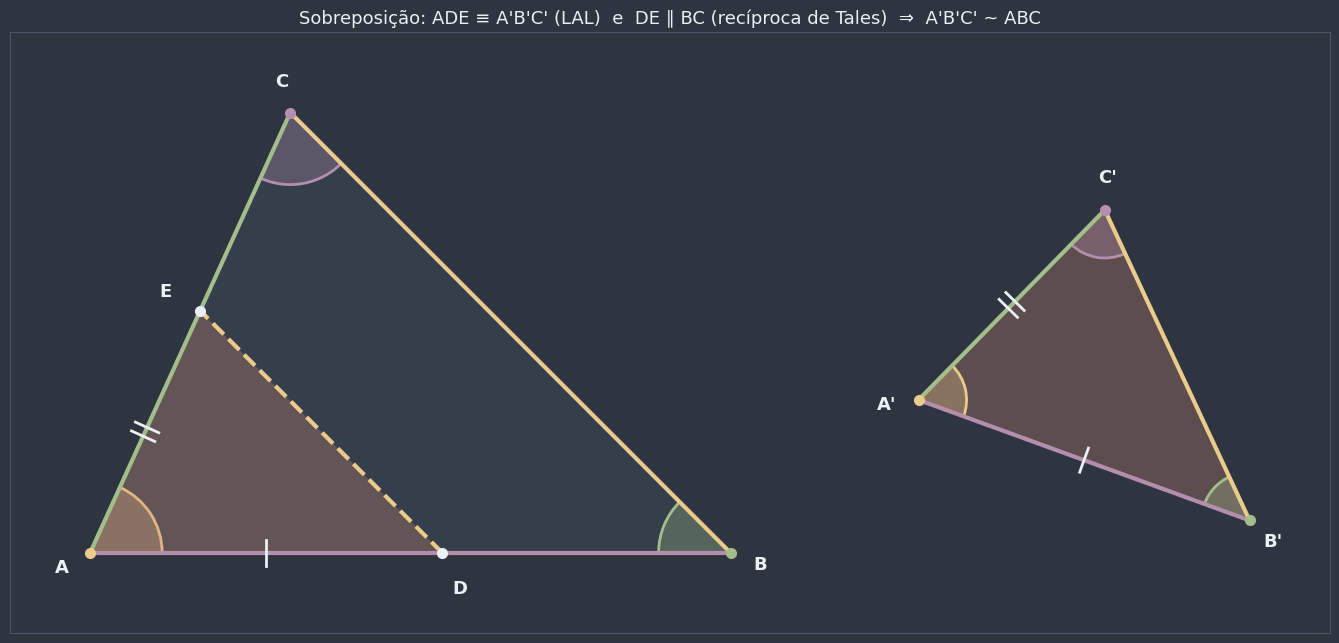

AD/AB = 0.5500   AE/AC = 0.5500
DE ∥ BC? True   DE = 4.2780   B'C' = 4.2780


In [11]:
t_grande = [np.array([0.0, 0.0]), np.array([8.0, 0.0]), np.array([2.5, 5.5])]
k_s = 0.55
t_pequeno = transformar(t_grande, k=k_s, rotacao=-20, destino=(12.5, 2.2))  # A'B'C', com k = 0,55
A_s, B_s, C_s = t_grande
D_s = A_s + (math.dist(*t_pequeno[:2]) / math.dist(A_s, B_s)) * (B_s - A_s)  # AD = A'B'
E_s = A_s + (math.dist(t_pequeno[0], t_pequeno[2]) / math.dist(A_s, C_s)) * (C_s - A_s)  # AE = A'C'

fig, ax = plt.subplots(figsize=(14, 6.5))
fig.patch.set_facecolor(NORD_FUNDO)
preparar_eixo(ax, t_grande + t_pequeno, margem=1.0)
desenhar_triangulo(ax, t_grande, "ABC", cor_preenchimento=COR_T1, opacidade=0.08, raio_angulo=0.9)
desenhar_triangulo(ax, t_pequeno, ("A'", "B'", "C'"), cor_preenchimento=COR_T2, opacidade=0.3, raio_angulo=0.6)
ax.add_patch(Polygon([A_s, D_s, E_s], closed=True, facecolor=COR_T2, alpha=0.3, edgecolor="none"))
desenhar_segmento(ax, D_s, E_s, cor=CORES_VERTICES[0], largura=3, estilo="--")
for P, Q in ((A_s, D_s), (t_pequeno[0], t_pequeno[1])):
    marcar_congruentes(ax, P, Q, tracos=1)
for P, Q in ((A_s, E_s), (t_pequeno[0], t_pequeno[2])):
    marcar_congruentes(ax, P, Q, tracos=2)
for X, nome in ((D_s, "D"), (E_s, "E")):
    desenhar_ponto(ax, X, cor=NORD_TEXTO)
    rotular_fora(ax, X, nome, sum(t_grande) / 3, distancia=0.5, tamanho=13)
ax.set_title("Sobreposição: ADE ≡ A'B'C' (LAL)  e  DE ∥ BC (recíproca de Tales)  ⇒  A'B'C' ~ ABC",
             color=NORD_TEXTO, fontsize=13)
plt.tight_layout()
plt.show()
print(f"AD/AB = {math.dist(A_s, D_s) / math.dist(A_s, B_s):.4f}   AE/AC = {math.dist(A_s, E_s) / math.dist(A_s, C_s):.4f}")
print(f"DE ∥ BC? {sao_paralelos(D_s, E_s, B_s, C_s)}   DE = {math.dist(D_s, E_s):.4f}   "
      f"B'C' = {math.dist(t_pequeno[1], t_pequeno[2]):.4f}")

⚠️ **Erros comuns:**

1. **LAL exige o ângulo entre os dois lados proporcionais.** Dois lados proporcionais e um ângulo **não** compreendido entre eles ("LLA") **não** é critério, pelo mesmo motivo do LLA na congruência ([`0405a_congruencia_de_triangulos.ipynb`](0405a_congruencia_de_triangulos.ipynb)): a circunferência pode cortar a semirreta em dois pontos, e saem dois triângulos de formatos diferentes.
2. **Em LLL, a proporção é entre lados correspondentes**: menor com menor, médio com médio, maior com maior (o ⚠️ da seção 1).
3. **AA precisa de dois ângulos.** Um ângulo congruente só não basta: dois triângulos com um ângulo de 40° podem ter formatos completamente diferentes.

**No código:** a função `criterios_semelhanca(t1, t2)` devolve a lista dos critérios satisfeitos, com a correspondência dada pela **ordem** dos vértices ($t_1[0] \leftrightarrow t_2[0]$, ...). As funções `triangulo_AA` e `triangulo_LAL` constroem um triângulo a partir dos dados de cada critério (para o LLL, já existe `triangulo_por_lados`). A tabela testa pares escolhidos para satisfazer cada critério e dois contraexemplos: o "LLA" (montado com os dois triângulos da ambiguidade) e um par com só um ângulo igual.

In [12]:
def criterios_semelhanca(t1, t2) -> list[str]:
    """Lista dos critérios de semelhança ("AA", "LAL", "LLL") satisfeitos pelos triângulos t1 = (A, B, C) e
    t2 = (A', B', C'), com a correspondência dada pela ORDEM dos vértices (A↔A', B↔B', C↔C')."""
    angulos_iguais = [math.isclose(x, y, abs_tol=1e-6) for x, y in zip(angulos(t1), angulos(t2))]
    razoes = [y / x for x, y in zip(lados(t1), lados(t2))]  # razoes[i]: lado oposto ao vértice i
    criterios = []
    if sum(angulos_iguais) >= 2:
        criterios.append("AA")
    for i in range(3):
        # os dois lados que saem do vértice i são os opostos aos outros dois vértices
        j, m = [x for x in range(3) if x != i]
        if angulos_iguais[i] and iguais(razoes[j], razoes[m]):
            criterios.append("LAL")
            break
    if iguais(razoes[0], razoes[1]) and iguais(razoes[1], razoes[2]):
        criterios.append("LLL")
    return criterios


def triangulo_AA(angulo_A: float, angulo_B: float, AB: float):
    """Triângulo com os ângulos Â e B̂ dados e o lado AB: C é o cruzamento dos lados que saem de A e de B."""
    A, B = np.array([0.0, 0.0]), np.array([AB, 0.0])
    return [A, B, cruzamento(A, angulo_A, B, 180 - angulo_B)]


def triangulo_LAL(AB: float, AC: float, angulo_A: float):
    """Triângulo com os lados AB e AC e o ângulo Â entre eles."""
    A = np.array([0.0, 0.0])
    return [A, np.array([AB, 0.0]), A + AC * direcao(angulo_A)]


# Contraexemplo LLA: B̂ = 30°, AB = 6 e AC = 4. A circunferência λ(A, 4) corta o outro lado de B̂ em DOIS pontos.
B_lla = np.array([0.0, 0.0])
A_lla = B_lla + 6 * direcao(30)
C1_lla, C2_lla = intersecoes_reta_circunferencia(A_lla, 4, B_lla, 0)

pares = {
    "AA: Â = 50°, B̂ = 70° nos dois": (triangulo_AA(50, 70, 5), transformar(triangulo_AA(50, 70, 8), rotacao=30)),
    "LAL: lados 4 e 6, e 6 e 9, com 40° entre eles": (triangulo_LAL(4, 6, 40),
                                                     transformar(triangulo_LAL(6, 9, 40), rotacao=-50)),
    "LLL: 4, 5, 6 e 6; 7,5; 9": (triangulo_por_lados(5, 6, 4),
                                 transformar(triangulo_por_lados(7.5, 9, 6), refletir=True)),
    "LLA (contraexemplo): AB, AC proporcionais e B̂ igual": ([A_lla, B_lla, C1_lla],
                                                            transformar([A_lla, B_lla, C2_lla], k=1.5)),
    "um ângulo só (contraexemplo): Â = 40°, lados 4, 6 e 5, 9": (triangulo_LAL(4, 6, 40), triangulo_LAL(5, 9, 40)),
}
linhas = []
for nome, (t1, t2) in pares.items():
    razoes = [l2 / l1 for l1, l2 in zip(lados(t1), lados(t2))]
    linhas.append({"par": nome, "criterios_semelhanca": ", ".join(criterios_semelhanca(t1, t2)) or "nenhum",
                   "semelhantes?": "sim" if semelhantes(t1, t2) else "não",
                   "ângulos (1º)": ", ".join(f"{a:.1f}°" for a in angulos(t1)),
                   "ângulos (2º)": ", ".join(f"{a:.1f}°" for a in angulos(t2)),
                   "razões a'/a, b'/b, c'/c": ", ".join(f"{r:.3f}" for r in razoes)})
display(pd.DataFrame(linhas).style.hide(axis="index"))

par,criterios_semelhanca,semelhantes?,ângulos (1º),ângulos (2º),"razões a'/a, b'/b, c'/c"
"AA: Â = 50°, B̂ = 70° nos dois","AA, LAL, LLL",sim,"50.0°, 70.0°, 60.0°","50.0°, 70.0°, 60.0°","1.600, 1.600, 1.600"
"LAL: lados 4 e 6, e 6 e 9, com 40° entre eles","AA, LAL, LLL",sim,"40.0°, 98.8°, 41.2°","40.0°, 98.8°, 41.2°","1.500, 1.500, 1.500"
"LLL: 4, 5, 6 e 6; 7,5; 9","AA, LAL, LLL",sim,"55.8°, 82.8°, 41.4°","55.8°, 82.8°, 41.4°","1.500, 1.500, 1.500"
"LLA (contraexemplo): AB, AC proporcionais e B̂ igual",nenhum,não,"18.6°, 30.0°, 131.4°","101.4°, 30.0°, 48.6°","4.612, 1.500, 1.500"
"um ângulo só (contraexemplo): Â = 40°, lados 4, 6 e 5, 9",nenhum,não,"40.0°, 98.8°, 41.2°","40.0°, 108.1°, 31.9°","1.560, 1.500, 1.250"


Nos três primeiros pares, o critério usado na construção garante **todos** os outros: cada par satisfaz AA, LAL **e** LLL, e as três razões coincidem. No contraexemplo LLA, as razões $\frac{c'}{c}$ e $\frac{b'}{b}$ (os lados $AB$ e $AC$) são iguais a 1,5 e o ângulo $\hat{B}$ é igual, mas os outros ângulos não batem: não há semelhança. No último par, só $\hat{A}$ é igual.

🕹️ **Widget interativo:** escolha um critério no seletor e mexa nos sliders dos **dados daquele critério** (os outros sliders são ignorados): para **AA**, use `Â`, `B̂` e `AB`; para **LAL**, `AB`, `AC` e `Â`; para **LLL**, `AB`, `AC` e `BC`. O notebook constrói **dois** triângulos com esses dados, o segundo com os comprimentos multiplicados por `k`, girado e deslocado. Depois **mede tudo** e confere que os elementos que **não** foram dados também ficaram proporcionais ou congruentes.

In [13]:
def construir_pelo_criterio(criterio: str, angulo_A: float, angulo_B: float, AB: float, AC: float, BC: float):
    """Triângulo construído só com os dados do critério escolhido (None se os dados não formam triângulo)."""
    if criterio == "AA":
        return triangulo_AA(angulo_A, angulo_B, AB) if angulo_A + angulo_B < 170 else None
    if criterio == "LAL":
        return triangulo_LAL(AB, AC, angulo_A)
    return triangulo_por_lados(BC, AC, AB)


def explorar_criterios(criterio: str, angulo_A: float, angulo_B: float, AB: float, AC: float, BC: float,
                       k: float) -> None:
    t1 = construir_pelo_criterio(criterio, angulo_A, angulo_B, AB, AC, BC)
    escala = 1 if criterio == "AA" else k  # em AA não há lados dados: o tamanho do 2º vem de A'B' = k · AB
    t2 = construir_pelo_criterio(criterio, angulo_A, angulo_B, AB * k, AC * escala, BC * escala)

    fig, (ax, ax_lista) = plt.subplots(1, 2, figsize=(15, 6.4), gridspec_kw={"width_ratios": [1.5, 1]})
    fig.patch.set_facecolor(NORD_FUNDO)
    if t1 is None or t2 is None:
        preparar_eixo(ax, [(0, 0), (1, 1)])
        ax.text(0.5, 0.5, "esses dados não formam triângulo", color=COR_ALERTA, fontsize=14, ha="center")
        escrever_checklist(ax_lista, [("a soma dos ângulos passou de 180°" if criterio == "AA"
                                       else "a desigualdade triangular falhou (0404a)", False)], "Sem triângulo")
        plt.show()
        return
    t1 = transformar(t1, destino=(0.0, 0.0))
    raio_1 = max(np.linalg.norm(p) for p in t1)
    t2 = transformar(t2, rotacao=-25)
    raio_2 = max(np.linalg.norm(p - sum(t2) / 3) for p in t2)
    t2 = transformar(t2, destino=(raio_1 + raio_2 + 1.5, 0.0))  # lado a lado, sem se sobrepor
    preparar_eixo(ax, t1 + t2, margem=1.2)
    desenhar_triangulo(ax, t1, "ABC", cor_preenchimento=COR_T1, raio_angulo=0.6)
    desenhar_triangulo(ax, t2, ("A'", "B'", "C'"), cor_preenchimento=COR_T2, raio_angulo=0.6 * max(k, 0.8))
    dados = {"AA": f"Â = {angulo_A:g}°, B̂ = {angulo_B:g}°", "LAL": f"AB = {AB:g}, AC = {AC:g}, Â = {angulo_A:g}°",
             "LLL": f"AB = {AB:g}, AC = {AC:g}, BC = {BC:g}"}[criterio]
    ax.set_title(f"Critério {criterio}: dados {dados}  (2º triângulo com k = {k:g})", color=NORD_TEXTO, fontsize=12)

    lados_1, lados_2, angulos_1, angulos_2 = lados(t1), lados(t2), angulos(t1), angulos(t2)
    dados_angulo = {"AA": (0, 1), "LAL": (0,), "LLL": ()}[criterio]
    dados_lado = {"AA": (), "LAL": (2, 1), "LLL": (0, 1, 2)}[criterio]
    itens = []
    for i, nome in enumerate(("B'C'/BC", "C'A'/CA", "A'B'/AB")):
        rotulo = "dado" if i in dados_lado else "medido"
        itens.append((f"{nome} = {lados_2[i] / lados_1[i]:.4f}  ({rotulo})", iguais(lados_2[i] / lados_1[i], k)))
    for i, nome in enumerate(("Â, Â'", "B̂, B̂'", "Ĉ, Ĉ'")):
        rotulo = "dado" if i in dados_angulo else "medido"
        itens.append((f"{nome}: {angulos_1[i]:.2f}° e {angulos_2[i]:.2f}°  ({rotulo})",
                      math.isclose(angulos_1[i], angulos_2[i], abs_tol=1e-6)))
    itens.append((f"criterios_semelhanca: {', '.join(criterios_semelhanca(t1, t2))}", True))
    escrever_checklist(ax_lista, itens, f"O critério {criterio} garantiu o resto")
    plt.tight_layout()
    plt.show()


widgets.interact(
    explorar_criterios,
    criterio=widgets.Dropdown(options=["AA", "LAL", "LLL"], value="AA", description="critério:"),
    angulo_A=widgets.FloatSlider(value=50, min=20, max=120, step=5, description="Â:"),
    angulo_B=widgets.FloatSlider(value=60, min=20, max=120, step=5, description="B̂:"),
    AB=widgets.FloatSlider(value=4.0, min=2.0, max=6.0, step=0.25, description="AB:"),
    AC=widgets.FloatSlider(value=5.0, min=2.0, max=6.0, step=0.25, description="AC:"),
    BC=widgets.FloatSlider(value=4.5, min=2.0, max=6.0, step=0.25, description="BC:"),
    k=widgets.FloatSlider(value=1.5, min=0.5, max=2.0, step=0.1, description="k:"),
);

interactive(children=(Dropdown(description='critério:', options=('AA', 'LAL', 'LLL'), value='AA'), FloatSlider…

📎 **Conexão (para a Trigonometria):** dois triângulos **retângulos** com um mesmo ângulo agudo $\alpha$ já têm **dois** ângulos iguais (o reto e $\alpha$): pelo critério AA, são semelhantes. Então as razões entre os lados, $\frac{\text{cateto oposto}}{\text{hipotenusa}}$, $\frac{\text{cateto adjacente}}{\text{hipotenusa}}$ e $\frac{\text{cateto oposto}}{\text{cateto adjacente}}$, **dependem só do ângulo**, e não do tamanho do triângulo. Essa é a ideia que dá origem ao **seno**, ao **cosseno** e à **tangente**, estudados em [`0509a_triangulos_retangulos.ipynb`](../05_trigonometria/0509a_triangulos_retangulos.ipynb). (Por isso as ferramentas deste notebook podem usar `cos` e `sin` para "apontar numa direção": eles são justamente essas razões.)

🎯 **Aplicação prática — projetores e fotografia:** a imagem projetada na parede é semelhante ao slide original. Afastar o projetor aumenta $k$ (a imagem cresce), mas os **ângulos** do desenho continuam os mesmos, e um retângulo continua retângulo com a mesma proporção. Numa câmera escura (ou num olho), a imagem invertida no fundo é semelhante ao objeto pelo critério AA: os raios que passam pelo furinho formam ângulos opostos pelo vértice.

**Pergunta de checagem:** dois triângulos têm ângulos de 40° e 75° (o primeiro) e de 75° e 65° (o segundo). São semelhantes? Por quê?

**Pergunta de checagem:** um triângulo tem lados 4, 6 e 8, e outro tem lados 6, 9 e 10. São semelhantes? Qual critério você testou?

## 4. Aplicações da semelhança

Agora o gancho pode ser resolvido com justificativa completa. Em cada problema, o trabalho é sempre o mesmo: **encontrar dois triângulos semelhantes**, dizer **por qual critério** e montar a proporção entre lados homólogos.

**1. Altura por sombras.** Um objeto de altura $h$ projeta uma sombra $s$; no mesmo instante, uma vara de altura $h'$ projeta uma sombra $s'$. Os dois triângulos (altura, sombra, raio de Sol) têm um **ângulo reto** no pé e o **mesmo ângulo** de inclinação do Sol, porque os raios são paralelos (ângulos correspondentes, [`0406a_paralelismo.ipynb`](0406a_paralelismo.ipynb)). Pelo critério **AA**, são semelhantes, e

$$\frac{h}{s} = \frac{h'}{s'} \quad\Longrightarrow\quad h = h' \cdot \frac{s}{s'}.$$

**2. Largura inacessível (rio, lago).** Na margem de cá, fique em frente a uma árvore $T$ da outra margem e finque o piquete $A$. Ande ao longo da margem até o piquete $B$ e continue, na mesma direção, até $C$. De $C$, ande perpendicularmente à margem, **afastando-se** do rio, até o ponto $D$ de onde a árvore $T$ e o piquete $B$ aparecem **alinhados**. Os triângulos $TAB$ e $DCB$ têm ângulos retos em $A$ e em $C$ e ângulos **opostos pelo vértice** em $B$ ([`0403a_angulos.ipynb`](0403a_angulos.ipynb)): pelo critério **AA**, $\triangle TAB \sim \triangle DCB$, e

$$\frac{AT}{CD} = \frac{AB}{CB} \quad\Longrightarrow\quad AT = CD \cdot \frac{AB}{CB}.$$

Só foram medidos três segmentos **em terra**: $AB$, $BC$ e $CD$.

**3. Escala, maquetes e ampliações.** A escala é a razão de semelhança. Perímetros e comprimentos ficam multiplicados por $k$, mas **áreas ficam multiplicadas por $k^2$**: dobrar as medidas quadruplica a área (📎 a demonstração vem em 📌 Áreas de Superfícies Planas).

**4. Teaser do próximo notebook.** Num triângulo retângulo, a **altura relativa à hipotenusa** divide o triângulo em **dois** triângulos retângulos menores, e **ambos são semelhantes ao original**: cada um tem um ângulo reto e compartilha um ângulo agudo com o triângulo grande (critério **AA**). As famosas **relações métricas** (como "cateto² = hipotenusa × projeção" e "altura² = produto das projeções") saem dessas semelhanças, e serão deduzidas em [`0416a_triangulos_retangulos.ipynb`](0416a_triangulos_retangulos.ipynb).

**No código:** as funções `altura_por_sombra` e `largura_inacessivel` são as duas proporções acima. A tabela resolve as situações do gancho (árvore), de um prédio e da pirâmide de Quéops, e um rio. Na pirâmide, há um detalhe que a lenda de Tales também precisa resolver: o "pé" da altura fica no **centro** da base, que é inacessível, e a sombra é medida a partir de lá: metade do lado da base (115 m) mais a parte visível da sombra.

In [14]:
def altura_por_sombra(h_ref: float, s_ref: float, s_obj: float) -> float:
    """Altura de um objeto pela sombra (critério AA): h / s_obj = h_ref / s_ref, no MESMO instante."""
    return h_ref * s_obj / s_ref


def largura_inacessivel(AB: float, BC: float, CD: float) -> float:
    """Largura AT do rio pela construção com piquetes: △TAB ~ △DCB (AA), logo AT = CD · AB / BC."""
    return CD * AB / BC


situacoes = [
    ("árvore do gancho", "vara de 1 m, sombra de 0,8 m; sombra da árvore: 9,6 m", altura_por_sombra(1.0, 0.8, 9.6)),
    ("prédio", "vara de 1,2 m, sombra de 0,9 m; sombra do prédio: 24 m", altura_por_sombra(1.2, 0.9, 24)),
    ("pirâmide de Quéops", "vara de 2 m, sombra de 3 m; sombra do centro da base: 115 + 104 = 219 m",
     altura_por_sombra(2.0, 3.0, 115 + 104)),
    ("largura do rio", "AB = 30 m, BC = 10 m, CD = 8 m", largura_inacessivel(30, 10, 8)),
]
display(pd.DataFrame([{"situação": s, "medidas acessíveis": m, "resultado (m)": f"{r:.2f}"}
                      for s, m, r in situacoes]).style.hide(axis="index"))

# Escala: uma planta na escala 1 : 100 (k = 100 do papel para a realidade)
k_planta = 100
comodos = {"sala": (5.0, 4.0), "quarto": (3.5, 3.0), "cozinha": (3.0, 2.5)}  # medidas no papel, em cm
linhas = []
for nome, (largura, comprimento) in comodos.items():
    linhas.append({"cômodo": nome, "no papel (cm)": f"{largura:g} × {comprimento:g}",
                   "perímetro no papel (cm)": f"{2 * (largura + comprimento):g}",
                   "perímetro real (m)": f"{2 * (largura + comprimento) * k_planta / 100:g}",
                   "área no papel (cm²)": f"{largura * comprimento:g}",
                   "área real (m²)": f"{largura * comprimento * k_planta**2 / 100**2:g}"})
display(pd.DataFrame(linhas).style.hide(axis="index"))

situação,medidas acessíveis,resultado (m)
árvore do gancho,"vara de 1 m, sombra de 0,8 m; sombra da árvore: 9,6 m",12.00
prédio,"vara de 1,2 m, sombra de 0,9 m; sombra do prédio: 24 m",32.00
pirâmide de Quéops,"vara de 2 m, sombra de 3 m; sombra do centro da base: 115 + 104 = 219 m",146.00
largura do rio,"AB = 30 m, BC = 10 m, CD = 8 m",24.00


cômodo,no papel (cm),perímetro no papel (cm),perímetro real (m),área no papel (cm²),área real (m²)
sala,5 × 4,18,18,20,20
quarto,3.5 × 3,13,13,10.5,10.5
cozinha,3 × 2.5,11,11,7.5,7.5


A pirâmide dá **146 m**, que é a altura original estimada da Grande Pirâmide de Gizé. Na planta, o perímetro da sala vai de 18 cm para 18 m (×100), mas a área vai de 20 cm² para 20 m², que é **10 000** vezes mais em cm² (1 m² = 10 000 cm²): a área multiplica por $k^2$.

A representação gráfica. À esquerda, a construção do rio, com os dois triângulos semelhantes destacados. À direita, o teaser: o triângulo retângulo $ABC$ (reto em $A$) dividido pela altura $\overline{AH}$, com os três triângulos semelhantes. A célula confere a semelhança com `criterios_semelhanca`, listando os vértices **na ordem da correspondência**: $\triangle ABC \sim \triangle HBA \sim \triangle HAC$.

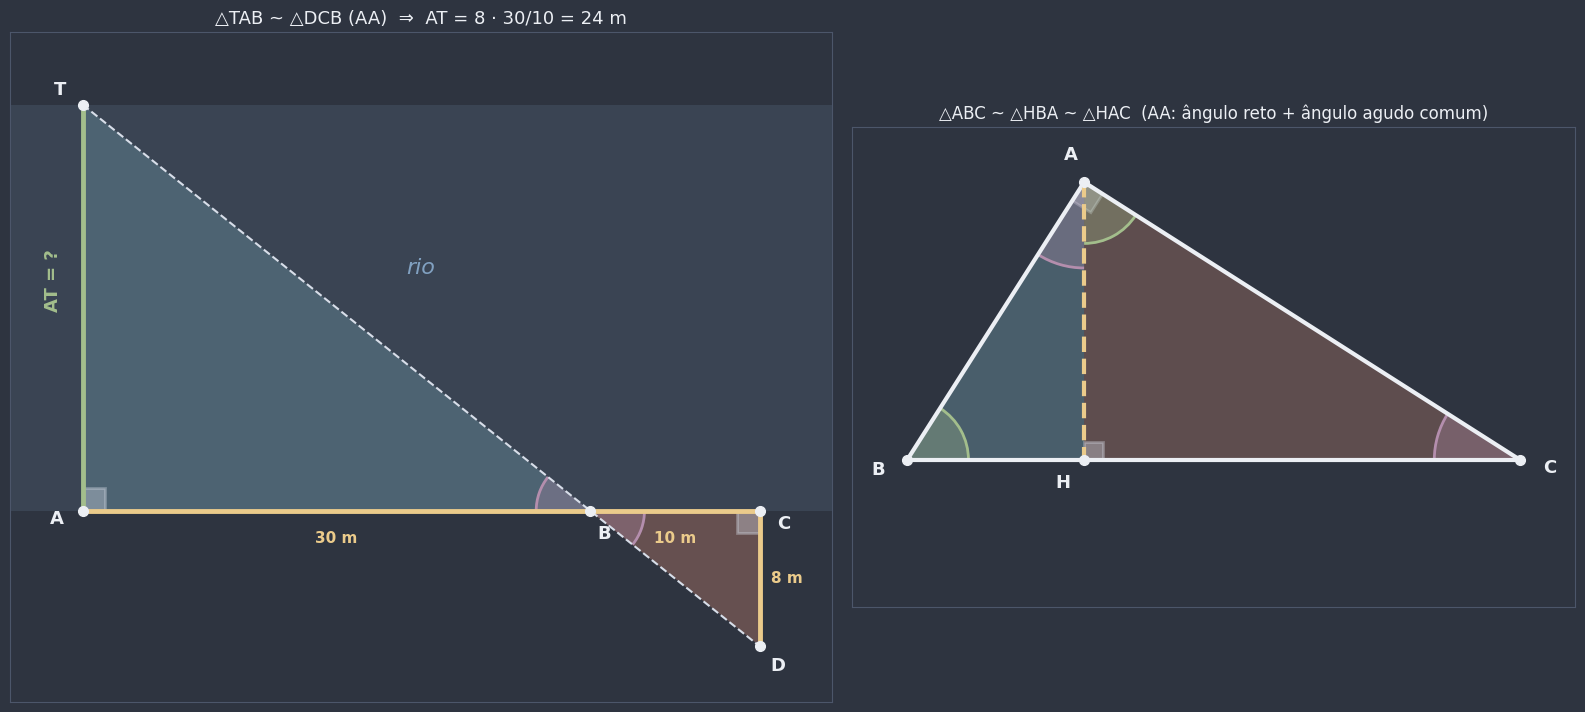

ABC e HBA: ['AA', 'LAL', 'LLL']
ABC e HAC: ['AA', 'LAL', 'LLL']
altura h = 4.5315, projeções m = 2.8869 e n = 7.1131;  h² = 20.5348  e  m·n = 20.5348


In [15]:
fig, (ax_rio, ax_ret) = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [1.15, 1]})
fig.patch.set_facecolor(NORD_FUNDO)

# O rio: margem de cá em y = 0, margem de lá em y = 24
T, A_r, B_r, C_r, D_r = (np.array(p, dtype=float) for p in ((0, 24), (0, 0), (30, 0), (40, 0), (40, -8)))
preparar_eixo(ax_rio, [(-4, -11), (44, 28)], margem=0.3)
ax_rio.add_patch(Rectangle((-5, 0), 50, 24, facecolor=COR_SECUNDARIA, alpha=0.15, edgecolor="none"))
ax_rio.text(20, 14, "rio", color=COR_SECUNDARIA, fontsize=16, ha="center", style="italic")
ax_rio.add_patch(Polygon([T, A_r, B_r], closed=True, facecolor=COR_T1, alpha=0.25, edgecolor="none"))
ax_rio.add_patch(Polygon([D_r, C_r, B_r], closed=True, facecolor=COR_T2, alpha=0.35, edgecolor="none"))
desenhar_segmento(ax_rio, T, D_r, cor=NORD_TEXTO_SEC, largura=1.5, estilo="--")  # a linha de visada
for P, Q, texto in ((A_r, B_r, "30 m"), (B_r, C_r, "10 m"), (C_r, D_r, "8 m")):
    desenhar_segmento(ax_rio, P, Q, cor=COR_AVISO, largura=3.5)
    rotular_segmento(ax_rio, P, Q, texto, cor=COR_AVISO, distancia=1.6, longe_de=(20, 10))
desenhar_segmento(ax_rio, A_r, T, cor=COR_DESTAQUE, largura=3.5)
ax_rio.text(-1.2, 12, "AT = ?", color=COR_DESTAQUE, fontsize=13, fontweight="bold", ha="right", rotation=90)
desenhar_arco(ax_rio, A_r, B_r, T, raio=2.2, cor=NORD_TEXTO_SEC)
desenhar_arco(ax_rio, C_r, B_r, D_r, raio=2.2, cor=NORD_TEXTO_SEC)
desenhar_arco(ax_rio, B_r, A_r, T, raio=3.2, cor=COR_EXTRA)
desenhar_arco(ax_rio, B_r, C_r, D_r, raio=3.2, cor=COR_EXTRA)
for X, nome in ((T, "T"), (A_r, "A"), (B_r, "B"), (C_r, "C"), (D_r, "D")):
    desenhar_ponto(ax_rio, X, cor=NORD_TEXTO)
    rotular_fora(ax_rio, X, nome, (25, 8), distancia=1.6, tamanho=13)
ax_rio.set_title(f"△TAB ~ △DCB (AA)  ⇒  AT = 8 · 30/10 = {largura_inacessivel(30, 10, 8):g} m",
                 color=NORD_TEXTO, fontsize=13)

# O teaser: triângulo retângulo em A e a altura relativa à hipotenusa
B_t, C_t = np.array([0.0, 0.0]), np.array([10.0, 0.0])
A_t = ponto_medio(B_t, C_t) + 5 * direcao(115)  # A na circunferência de diâmetro BC: ângulo reto em A (0413a)
H_t = np.array([A_t[0], 0.0])  # pé da altura (BC está sobre o eixo x)
preparar_eixo(ax_ret, [B_t, C_t, A_t, (5, -1.5)], margem=0.9)
ax_ret.add_patch(Polygon([H_t, B_t, A_t], closed=True, facecolor=COR_T1, alpha=0.3, edgecolor="none"))
ax_ret.add_patch(Polygon([H_t, A_t, C_t], closed=True, facecolor=COR_T2, alpha=0.3, edgecolor="none"))
for P, Q in ((A_t, B_t), (A_t, C_t), (B_t, C_t)):
    desenhar_segmento(ax_ret, P, Q, cor=NORD_TEXTO, largura=3)
desenhar_segmento(ax_ret, A_t, H_t, cor=COR_AVISO, largura=3, estilo="--")
desenhar_arco(ax_ret, A_t, B_t, C_t, raio=0.6, cor=NORD_TEXTO_SEC)
desenhar_arco(ax_ret, H_t, C_t, A_t, raio=0.5, cor=NORD_TEXTO_SEC)
desenhar_arco(ax_ret, B_t, C_t, A_t, raio=1.0, cor=CORES_VERTICES[1])
desenhar_arco(ax_ret, A_t, H_t, C_t, raio=1.0, cor=CORES_VERTICES[1])
desenhar_arco(ax_ret, C_t, A_t, B_t, raio=1.4, cor=CORES_VERTICES[2])
desenhar_arco(ax_ret, A_t, B_t, H_t, raio=1.4, cor=CORES_VERTICES[2])
for X, nome in ((A_t, "A"), (B_t, "B"), (C_t, "C"), (H_t, "H")):
    desenhar_ponto(ax_ret, X, cor=NORD_TEXTO)
    rotular_fora(ax_ret, X, nome, (A_t + B_t + C_t) / 3, distancia=0.5, tamanho=13)
ax_ret.set_title("△ABC ~ △HBA ~ △HAC  (AA: ângulo reto + ângulo agudo comum)", color=NORD_TEXTO, fontsize=12)
plt.tight_layout()
plt.show()

print("ABC e HBA:", criterios_semelhanca([A_t, B_t, C_t], [H_t, B_t, A_t]))
print("ABC e HAC:", criterios_semelhanca([A_t, B_t, C_t], [H_t, A_t, C_t]))
h, m, n = math.dist(A_t, H_t), math.dist(B_t, H_t), math.dist(H_t, C_t)
print(f"altura h = {h:.4f}, projeções m = {m:.4f} e n = {n:.4f};  h² = {h**2:.4f}  e  m·n = {m * n:.4f}")

O último `print` já mostra uma das relações métricas, $h^2 = m \cdot n$, que você vai **deduzir** (e não só conferir) em [`0416a_triangulos_retangulos.ipynb`](0416a_triangulos_retangulos.ipynb). Os ângulos verdes são o $\hat{B}$ do triângulo grande e o seu congruente em $HAC$; os roxos, o $\hat{C}$ e o seu congruente em $HBA$.

🕹️ **Widget interativo — o erro do horário:** a árvore tem **12 m** de verdade (a "resposta" escondida). O slider `vara` é a altura da vara de referência, `Sol` é a inclinação do Sol no momento em que a sombra da vara é medida, e `atraso` é quanto tempo depois você mede a sombra da árvore (de manhã, o Sol sobe cerca de 15° por hora). Com atraso zero, a estimativa é **exata**, para qualquer vara e qualquer Sol. Aumente o atraso e veja a estimativa se afastar dos 12 m.

In [16]:
def explorar_sombras(altura_vara: float, inclinacao_sol: float, atraso: int) -> None:
    altura_real = 12.0
    sol_arvore = inclinacao_sol + 0.25 * atraso  # o Sol sobe ~0,25° por minuto
    # sombra = altura ÷ tangente da inclinação (a tangente vem da Trigonometria; aqui só monta a simulação)
    s_vara = altura_vara / math.tan(math.radians(inclinacao_sol))
    s_arvore = altura_real / math.tan(math.radians(sol_arvore))
    estimada = altura_por_sombra(altura_vara, s_vara, s_arvore)

    pe_v, pe_a = np.array([0.0, 0.0]), np.array([6.0, 0.0])
    fig, (ax, ax_lista) = plt.subplots(1, 2, figsize=(15, 6.2), gridspec_kw={"width_ratios": [1.6, 1]})
    fig.patch.set_facecolor(NORD_FUNDO)
    preparar_eixo(ax, [(-1, -1.2), (33, 13.5)], margem=0.2)
    ax.axhline(0, color=NORD_TEXTO_SEC, lw=2)
    for pe, h, s, sol, cor in ((pe_v, altura_vara, s_vara, inclinacao_sol, COR_T1),
                               (pe_a, altura_real, s_arvore, sol_arvore, COR_T2)):
        topo, ponta = pe + (0, h), pe + (s, 0)
        ax.add_patch(Polygon([pe, topo, ponta], closed=True, facecolor=cor, alpha=0.25, edgecolor="none"))
        desenhar_segmento(ax, pe, topo, cor=COR_DESTAQUE, largura=5)
        desenhar_segmento(ax, pe, ponta, cor=COR_EXTRA, largura=5)
        desenhar_segmento(ax, topo, ponta, cor=COR_AVISO, largura=1.8, estilo="--")
        rotulo = f"{sol:.1f}°" if h > 5 else None  # na vara (pequena), o valor fica só no painel
        desenhar_arco(ax, ponta, topo, pe, raio=1.0 if h > 5 else 0.4, cor=COR_AVISO, rotulo=rotulo, raio_rotulo=2.0)
        ax.text(pe[0] + s / 2, -0.75, f"{s:.2f} m", color=COR_EXTRA, fontsize=11, ha="center")
    ax.set_title(f"estimativa: {estimada:.2f} m   (altura real: {altura_real:g} m)",
                 color=COR_DESTAQUE if math.isclose(estimada, altura_real, rel_tol=1e-9) else COR_ALERTA, fontsize=13)
    itens = [
        (f"vara: {altura_vara:.2f} m, sombra {s_vara:.2f} m (Sol a {inclinacao_sol:g}°)", True),
        (f"árvore: sombra {s_arvore:.2f} m, medida {atraso} min depois (Sol a {sol_arvore:.1f}°)", True),
        (f"mesmo ângulo do Sol nos dois triângulos (AA)", atraso == 0),
        (f"h = {altura_vara:.2f} · {s_arvore:.2f} / {s_vara:.2f} = {estimada:.2f} m", True),
        (f"erro: {estimada - altura_real:+.2f} m ({(estimada - altura_real) / altura_real:+.0%})",
         math.isclose(estimada, altura_real, rel_tol=1e-9)),
    ]
    escrever_checklist(ax_lista, itens, "Altura pela sombra")
    plt.tight_layout()
    plt.show()


widgets.interact(
    explorar_sombras,
    altura_vara=widgets.FloatSlider(value=1.0, min=0.5, max=2.0, step=0.1, description="vara (m):"),
    inclinacao_sol=widgets.FloatSlider(value=45, min=25, max=65, step=1, description="Sol (°):"),
    atraso=widgets.IntSlider(value=0, min=0, max=90, step=5, description="atraso (min):"),
);

interactive(children=(FloatSlider(value=1.0, description='vara (m):', max=2.0, min=0.5), FloatSlider(value=45.…

💡 **Dica:** antes de montar a proporção, escreva **o que corresponde a quê**: "altura da vara ↔ altura da árvore, sombra da vara ↔ sombra da árvore". A proporção sai dessa lista ($\frac{\text{altura}}{\text{altura}} = \frac{\text{sombra}}{\text{sombra}}$, ou $\frac{\text{altura}}{\text{sombra}} = \frac{\text{altura}}{\text{sombra}}$), e não há como inverter sem perceber.

⚠️ **Erro comum:** achar que as sombras são proporcionais às alturas em **qualquer** momento. A proporção vale para sombras medidas **ao mesmo tempo** (mesmo ângulo do Sol, o "A" do critério AA). Como o widget mostrou, uma hora de atraso pode errar a altura em vários metros.

🎯 **Aplicação prática — topografia e triangulação:** antes do GPS, mapas inteiros eram feitos medindo **uma** distância com cuidado (a "base") e, a partir dela, só ângulos: cada novo ponto formava um triângulo com dois pontos já conhecidos. É a **triangulação geodésica**, que mediu países e até o tamanho da Terra. Em pequena escala, a mesma ideia mede torres, árvores e prédios com uma vara, uma trena, ou um espelho no chão (o ângulo de reflexão faz o papel do Sol).

**Pergunta de checagem:** uma vara de 1,5 m projeta uma sombra de 2 m. No mesmo instante, um poste projeta uma sombra de 10 m. Qual é a altura do poste?

**Pergunta de checagem:** na construção do rio, por que foi importante que $D$, $B$ e $T$ ficassem **alinhados**? Qual ângulo da semelhança depende disso?

## 5. Potência de ponto

Hora de responder ao segundo mistério do gancho. O ponto de partida são **três relações** entre pedaços de cordas, secantes e tangentes. As três se demonstram com o critério **AA** da seção 3, e os ângulos iguais vêm todos de [`0413a_angulos_na_circunferencia.ipynb`](0413a_angulos_na_circunferencia.ipynb).

**1. Duas cordas que se cortam num ponto interior $P$.** Se as cordas $\overline{AB}$ e $\overline{CD}$ se cortam em $P$, então

$$PA \cdot PB = PC \cdot PD.$$

| Passo | Afirmação | Justificativa |
|---|---|---|
| 1 | $A\hat{P}D \equiv C\hat{P}B$ | ângulos **opostos pelo vértice** ([`0403a_angulos.ipynb`](0403a_angulos.ipynb)) |
| 2 | $P\hat{A}D \equiv P\hat{C}B$ | são os ângulos inscritos $B\hat{A}D$ e $B\hat{C}D$, que **enxergam o mesmo arco** $\overset{\frown}{BD}$ ([`0413a_angulos_na_circunferencia.ipynb`](0413a_angulos_na_circunferencia.ipynb)) |
| 3 | $\triangle PAD \sim \triangle PCB$ | critério **AA** (seção 3), com $P \leftrightarrow P$, $A \leftrightarrow C$, $D \leftrightarrow B$ |
| 4 | $\dfrac{PA}{PC} = \dfrac{PD}{PB}$ | lados homólogos: $\overline{PA}$ e $\overline{PC}$ são opostos aos ângulos em $D$ e $B$; $\overline{PD}$ e $\overline{PB}$, aos ângulos em $A$ e $C$ |
| 5 | $PA \cdot PB = PC \cdot PD$ | produto dos meios = produto dos extremos ([`0414a_teorema_de_tales.ipynb`](0414a_teorema_de_tales.ipynb)) |

**2. Duas secantes que saem de um ponto exterior $P$.** A primeira corta a circunferência em $A$ (o ponto mais próximo de $P$) e $B$; a segunda, em $C$ (mais próximo) e $D$. Então, de novo, $PA \cdot PB = PC \cdot PD$.

*Demonstração:* os triângulos $PBC$ e $PDA$ têm o ângulo $\hat{P}$ **comum**, e $P\hat{B}C \equiv P\hat{D}A$, porque são os ângulos inscritos $A\hat{B}C$ e $C\hat{D}A$, que enxergam o mesmo arco $\overset{\frown}{AC}$ ([`0413a_angulos_na_circunferencia.ipynb`](0413a_angulos_na_circunferencia.ipynb)). Por AA, $\triangle PBC \sim \triangle PDA$, e daí $\frac{PB}{PD} = \frac{PC}{PA}$, isto é, $PA \cdot PB = PC \cdot PD$. ∎

**3. Uma secante e uma tangente que saem de um ponto exterior $P$.** Se $\overline{PT}$ é tangente ($T$ é o ponto de tangência) e a secante por $P$ corta a circunferência em $A$ (mais próximo) e $B$, então

$$PT^2 = PA \cdot PB.$$

*Demonstração:* os triângulos $PTA$ e $PBT$ têm o ângulo $\hat{P}$ comum, e $P\hat{T}A \equiv T\hat{B}A$: o primeiro é um **ângulo de segmento** (tangente + corda $\overline{TA}$) e o segundo é um ângulo **inscrito**, e os dois enxergam o mesmo arco $\overset{\frown}{TA}$ ([`0413a_angulos_na_circunferencia.ipynb`](0413a_angulos_na_circunferencia.ipynb)). Por AA, $\triangle PTA \sim \triangle PBT$, e daí $\frac{PT}{PB} = \frac{PA}{PT}$, isto é, $PT^2 = PA \cdot PB$. ∎

### A unificação: a potência de um ponto

As três relações dizem a mesma coisa: **para um ponto $P$ fixo, o produto $PA \cdot PB$ é o mesmo para qualquer reta que passa por $P$ e corta a circunferência em $A$ e $B$** (na tangente, $A = B = T$ e o produto vira $PT^2$). Quanto vale esse produto? Como ele não depende da reta, basta calcular numa reta **especial**, a que passa pelo centro $O$. Seja $d = OP$ e $r$ o raio:

- se $P$ é **exterior**, essa reta corta a circunferência a $PA = d - r$ e $PB = d + r$ de $P$, e o produto é $(d - r)(d + r) = d^2 - r^2$;
- se $P$ é **interior**, os dois pedaços do diâmetro medem $r - d$ e $r + d$, e o produto é $r^2 - d^2$.

📌 **Definição formal (potência de um ponto):** a **potência** do ponto $P$ em relação à circunferência $\lambda(O, r)$ é o número

$$\operatorname{Pot}(P) = OP^2 - r^2,$$

que é **positivo** se $P$ é exterior, **zero** se $P$ está sobre a circunferência e **negativo** se $P$ é interior. Para **qualquer** reta que passa por $P$ e corta a circunferência em $A$ e $B$:

$$PA \cdot PB = |\operatorname{Pot}(P)|, \qquad \text{e, se } P \text{ é exterior, } PT^2 = \operatorname{Pot}(P).$$

O mistério do gancho está resolvido: lá, $r = 5$ e $OP^2 = 3^2 + 1{,}5^2 = 11{,}25$, então todo produto vale $|11{,}25 - 25| = 13{,}75$.

**No código:** a função `intersecoes_reta_circunferencia(O, r, P, angulo)`, da primeira célula, escreve os pontos da reta como $X = P + t\,u$ (com $u$ de tamanho 1) e impõe $|X - O|^2 = r^2$. Sai uma equação do 2º grau em $t$, e cada raiz $t$ é a distância (com sinal) de $P$ até um ponto de interseção. A tabela calcula $PA \cdot PB$ em 12 direções para um ponto interior e 12 para um ponto exterior, e compara com $|OP^2 - r^2|$. Para a tangente, a função `pontos_de_tangencia` acha $T$ cruzando a circunferência com a de diâmetro $\overline{OP}$ (o ângulo reto em $T$ de [`0412a_circunferencia_e_circulo.ipynb`](0412a_circunferencia_e_circulo.ipynb)).

In [17]:
def potencia(O, r: float, P) -> float:
    """Potência do ponto P em relação à circunferência λ(O, r): OP² − r²."""
    return math.dist(O, P) ** 2 - r**2


def pontos_de_tangencia(O, r: float, P):
    """Pontos T1 e T2 em que as tangentes traçadas por P tocam λ(O, r): o cruzamento de λ(O, r) com a
    circunferência de diâmetro OP (0412a). Devolve None se P não for exterior."""
    O, P = np.asarray(O, dtype=float), np.asarray(P, dtype=float)
    d = math.dist(O, P)
    if d <= r + 1e-9:
        return None
    u = (P - O) / d
    normal = np.array([-u[1], u[0]])
    a = r**2 / d  # distância de O até a corda T1T2 (subtraindo as equações das duas circunferências)
    h = math.sqrt(r**2 - a**2)
    return O + a * u + h * normal, O + a * u - h * normal


O_p, r_p = np.array([0.0, 0.0]), 5.0
P_int, P_ext = np.array([2.0, 1.0]), np.array([8.5, 0.0])
linhas = []
for rotulo, P, direcoes in (("interior", P_int, np.arange(0, 180, 15)),
                            ("exterior", P_ext, 180 + np.linspace(-34, 34, 12))):
    for angulo in direcoes:
        X1, X2 = intersecoes_reta_circunferencia(O_p, r_p, P, angulo)
        PA, PB = math.dist(P, X1), math.dist(P, X2)
        linhas.append({"P": rotulo, "direção da reta": f"{angulo % 360:.1f}°", "PA": f"{min(PA, PB):.4f}",
                       "PB": f"{max(PA, PB):.4f}", "PA · PB": f"{PA * PB:.6f}",
                       "|OP² − r²|": f"{abs(potencia(O_p, r_p, P)):.6f}"})
display(pd.DataFrame(linhas).style.hide(axis="index"))

T1, T2 = pontos_de_tangencia(O_p, r_p, P_ext)
u_t = direcao(direcao_de(P_ext, T1))
w_t = P_ext - O_p
delta_t = (2 * np.dot(u_t, w_t)) ** 2 - 4 * (np.dot(w_t, w_t) - r_p**2)
print(f"tangente: T = ({T1[0]:.4f}, {T1[1]:.4f}),  PT² = {math.dist(P_ext, T1) ** 2:.6f},  "
      f"Pot(P) = {potencia(O_p, r_p, P_ext):.6f}")
print(f"discriminante da equação na direção de PT: {delta_t:.1e}  (zero: a reta só toca a circunferência)")
print(f"ângulo OTP = {medir_angulo(T1, O_p, P_ext):.4f}°  (tangente perpendicular ao raio, 0412a)")

P,direção da reta,PA,PB,PA · PB,|OP² − r²|
interior,0.0°,2.8990,6.8990,20.000000,20.000000
interior,15.0°,2.7892,7.1705,20.000000,20.000000
interior,30.0°,2.7662,7.2303,20.000000,20.000000
interior,45.0°,2.8284,7.0711,20.000000,20.000000
interior,60.0°,2.9798,6.7119,20.000000,20.000000
interior,75.0°,3.2282,6.1954,20.000000,20.000000
interior,90.0°,3.5826,5.5826,20.000000,20.000000
interior,105.0°,4.0463,4.9428,20.000000,20.000000
interior,120.0°,4.3402,4.6081,20.000000,20.000000
interior,135.0°,3.8206,5.2348,20.000000,20.000000


tangente: T = (2.9412, 4.0434),  PT² = 47.250000,  Pot(P) = 47.250000
discriminante da equação na direção de PT: -2.8e-14  (zero: a reta só toca a circunferência)
ângulo OTP = 90.0000°  (tangente perpendicular ao raio, 0412a)


Nas 24 linhas, $PA \cdot PB$ coincide com $|OP^2 - r^2|$ (47,25 para o ponto exterior e 20 para o interior). Na direção da tangente, o discriminante é zero: a equação do 2º grau tem **raiz dupla**, os dois pontos $A$ e $B$ se fundem em $T$, e $PA \cdot PB$ vira $PT^2$.

📎 **Conexão — uma segunda demonstração, algébrica:** a equação da função é $t^2 + 2(u \cdot w)\,t + (|w|^2 - r^2) = 0$. Pela relação entre **coeficientes e raízes** de [`0109a_funcao_quadratica_sinal_inequacoes_e_raizes.ipynb`](../01_conjuntos_e_funcoes/0109a_funcao_quadratica_sinal_inequacoes_e_raizes.ipynb), o **produto das raízes** é $\frac{c}{a} = |w|^2 - r^2 = OP^2 - r^2$, qualquer que seja a direção $u$! É a potência de ponto inteira em uma linha de álgebra (o sinal negativo, para $P$ interior, aparece porque as duas raízes têm sinais contrários: os pontos ficam um de cada lado de $P$).

A representação gráfica dos três casos, com cores fixas para os produtos: $PA \cdot PB$ em **amarelo**, $PC \cdot PD$ em **verde** e $PT^2$ em **roxo**. Os dois triângulos semelhantes de cada demonstração estão sombreados.

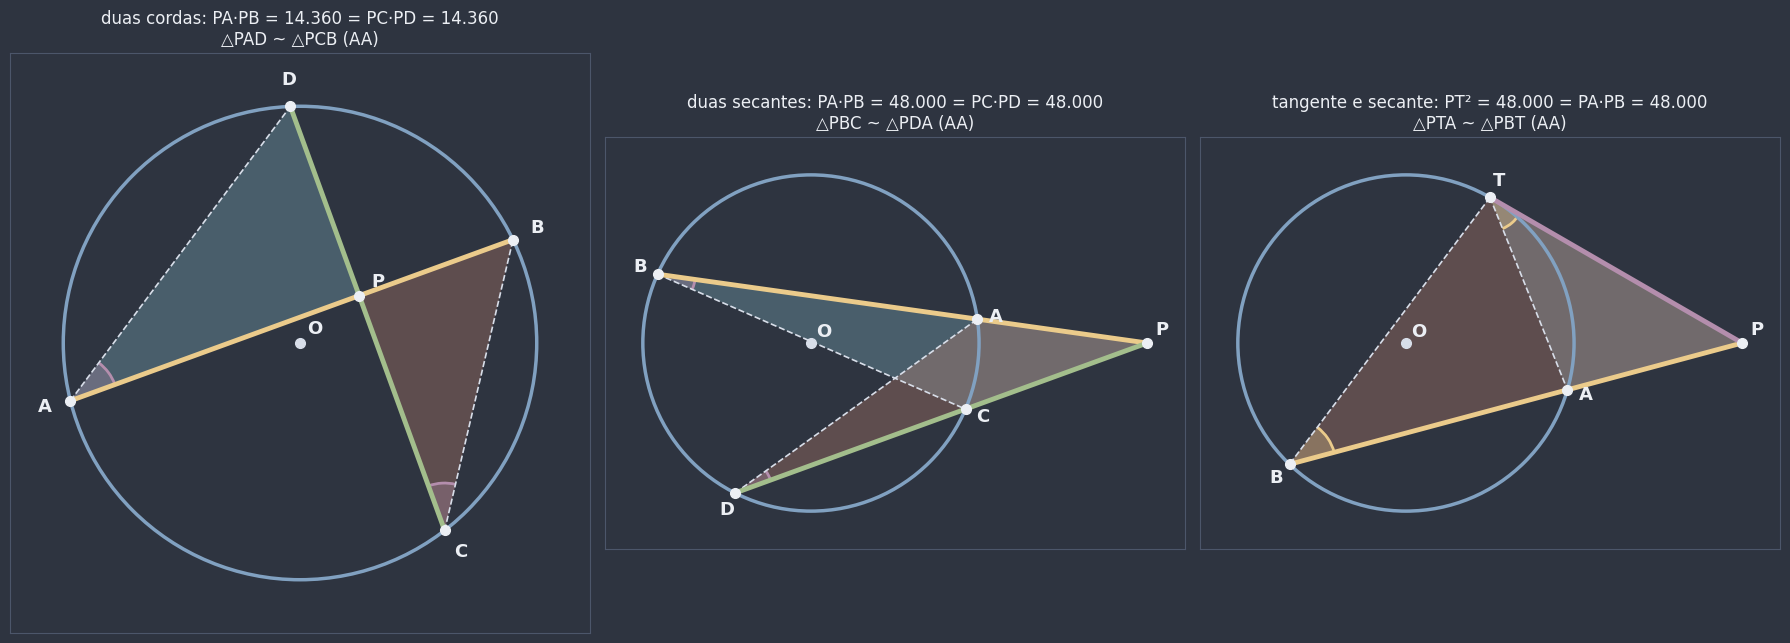

In [18]:
def nomear(ax, pontos_e_nomes, centro, distancia: float = 0.45) -> None:
    for X, nome in pontos_e_nomes:
        desenhar_ponto(ax, X, cor=NORD_TEXTO)
        rotular_fora(ax, X, nome, centro, distancia=distancia, tamanho=13)


O_f, r_f = np.array([0.0, 0.0]), 4.0
fig, eixos = plt.subplots(1, 3, figsize=(18, 6.6))
fig.patch.set_facecolor(NORD_FUNDO)

# Caso 1: duas cordas por P interior
ax = eixos[0]
P1 = np.array([1.0, 0.8])
A1, B1 = intersecoes_reta_circunferencia(O_f, r_f, P1, 20)
C1, D1 = intersecoes_reta_circunferencia(O_f, r_f, P1, 110)
preparar_eixo(ax, [(-4, -4), (4, 4)], margem=0.9)
desenhar_circunferencia(ax, O_f, r_f, cor=COR_CIRCULO)
ax.add_patch(Polygon([P1, A1, D1], closed=True, facecolor=COR_T1, alpha=0.3, edgecolor="none"))
ax.add_patch(Polygon([P1, C1, B1], closed=True, facecolor=COR_T2, alpha=0.3, edgecolor="none"))
for P, Q in ((A1, D1), (C1, B1)):
    desenhar_segmento(ax, P, Q, cor=NORD_TEXTO_SEC, largura=1.2, estilo="--")
desenhar_segmento(ax, A1, B1, cor=COR_PA_PB, largura=3.5)
desenhar_segmento(ax, C1, D1, cor=COR_PC_PD, largura=3.5)
desenhar_arco(ax, A1, B1, D1, raio=0.8, cor=COR_EXTRA)
desenhar_arco(ax, C1, B1, D1, raio=0.8, cor=COR_EXTRA)
nomear(ax, ((A1, "A"), (B1, "B"), (C1, "C"), (D1, "D")), O_f)
desenhar_ponto(ax, P1, "P", cor=NORD_TEXTO, deslocamento=(0.2, 0.15))
ax.set_title(f"duas cordas: PA·PB = {math.dist(P1, A1) * math.dist(P1, B1):.3f} = "
             f"PC·PD = {math.dist(P1, C1) * math.dist(P1, D1):.3f}\n△PAD ~ △PCB (AA)", color=NORD_TEXTO, fontsize=12)

# Caso 2: duas secantes por P exterior
ax = eixos[1]
P2 = np.array([8.0, 0.0])
A2, B2 = intersecoes_reta_circunferencia(O_f, r_f, P2, 172)
C2, D2 = intersecoes_reta_circunferencia(O_f, r_f, P2, 200)
preparar_eixo(ax, [(-4, -4), (8, 4)], margem=0.9)
desenhar_circunferencia(ax, O_f, r_f, cor=COR_CIRCULO)
ax.add_patch(Polygon([P2, B2, C2], closed=True, facecolor=COR_T1, alpha=0.3, edgecolor="none"))
ax.add_patch(Polygon([P2, D2, A2], closed=True, facecolor=COR_T2, alpha=0.3, edgecolor="none"))
for P, Q in ((B2, C2), (D2, A2)):
    desenhar_segmento(ax, P, Q, cor=NORD_TEXTO_SEC, largura=1.2, estilo="--")
desenhar_segmento(ax, P2, B2, cor=COR_PA_PB, largura=3.5)
desenhar_segmento(ax, P2, D2, cor=COR_PC_PD, largura=3.5)
desenhar_arco(ax, B2, A2, C2, raio=0.9, cor=COR_EXTRA)
desenhar_arco(ax, D2, C2, A2, raio=0.9, cor=COR_EXTRA)
nomear(ax, ((A2, "A"), (B2, "B"), (C2, "C"), (D2, "D")), O_f)
desenhar_ponto(ax, P2, "P", cor=NORD_TEXTO, deslocamento=(0.2, 0.2))
ax.set_title(f"duas secantes: PA·PB = {math.dist(P2, A2) * math.dist(P2, B2):.3f} = "
             f"PC·PD = {math.dist(P2, C2) * math.dist(P2, D2):.3f}\n△PBC ~ △PDA (AA)", color=NORD_TEXTO, fontsize=12)

# Caso 3: tangente e secante por P exterior
ax = eixos[2]
P3 = np.array([8.0, 0.0])
T3, _ = pontos_de_tangencia(O_f, r_f, P3)
A3, B3 = intersecoes_reta_circunferencia(O_f, r_f, P3, 195)
preparar_eixo(ax, [(-4, -4), (8, 4)], margem=0.9)
desenhar_circunferencia(ax, O_f, r_f, cor=COR_CIRCULO)
ax.add_patch(Polygon([P3, T3, A3], closed=True, facecolor=COR_T1, alpha=0.3, edgecolor="none"))
ax.add_patch(Polygon([P3, B3, T3], closed=True, facecolor=COR_T2, alpha=0.3, edgecolor="none"))
for P, Q in ((T3, A3), (T3, B3)):
    desenhar_segmento(ax, P, Q, cor=NORD_TEXTO_SEC, largura=1.2, estilo="--")
desenhar_segmento(ax, P3, B3, cor=COR_PA_PB, largura=3.5)
desenhar_segmento(ax, P3, T3, cor=COR_PT, largura=3.5)
desenhar_arco(ax, T3, P3, A3, raio=0.8, cor=COR_AVISO)
desenhar_arco(ax, B3, T3, A3, raio=1.1, cor=COR_AVISO)
nomear(ax, ((A3, "A"), (B3, "B"), (T3, "T")), O_f)
desenhar_ponto(ax, P3, "P", cor=NORD_TEXTO, deslocamento=(0.2, 0.2))
ax.set_title(f"tangente e secante: PT² = {math.dist(P3, T3) ** 2:.3f} = "
             f"PA·PB = {math.dist(P3, A3) * math.dist(P3, B3):.3f}\n△PTA ~ △PBT (AA)", color=NORD_TEXTO, fontsize=12)
for ax in eixos:
    desenhar_ponto(ax, O_f, "O", cor=NORD_TEXTO_SEC)
plt.tight_layout()
plt.show()

Os ângulos marcados com a mesma cor são os ângulos inscritos (ou de segmento) que enxergam o mesmo arco: o "segundo A" do critério AA em cada demonstração.

🕹️ **Widget interativo:** o slider `OP` afasta o ponto $P$ do centro (o raio é 3: com $OP < 3$, $P$ é interior; com $OP > 3$, exterior), e o slider `ângulo` gira a reta que passa por $P$. No modo **medidas**, o painel mostra $PA$, $PB$, o produto e $|OP^2 - r^2|$: gire a reta e veja o produto **parado** enquanto $P$ não se mexe. A reta tracejada é a que passa pelo centro, a da unificação. Procure o momento em que a reta fica **tangente** (a figura avisa, e $PA = PB = PT$), ou marque `travar na tangente`. No modo **quadratura**, o painel desenha o quadrado de lado $\sqrt{|\operatorname{Pot}(P)|}$ (roxo; com $P$ exterior, o lado é $PT$) e o retângulo $PA \times PB$ (amarelo): formatos diferentes, **mesma área**.

In [19]:
def explorar_potencia(OP: float, angulo: float, modo: str, travar_tangente: bool) -> None:
    O_w, r_w = np.array([0.0, 0.0]), 3.0
    P_w = np.array([OP, 0.0])
    pot = potencia(O_w, r_w, P_w)
    tangentes = pontos_de_tangencia(O_w, r_w, P_w)
    angulos_tangentes = [] if tangentes is None else [direcao_de(P_w, T) % 180 for T in tangentes]
    if travar_tangente and tangentes is not None:
        angulo = angulos_tangentes[0]
    tangente = any(min(abs(angulo - a), 180 - abs(angulo - a)) < 0.6 for a in angulos_tangentes)
    if tangente:
        angulo = min(angulos_tangentes, key=lambda a: min(abs(angulo - a), 180 - abs(angulo - a)))
    pontos = intersecoes_reta_circunferencia(O_w, r_w, P_w, angulo)
    if tangente and len(pontos) != 1:
        pontos = [tangentes[angulos_tangentes.index(angulo)]]

    fig, (ax, ax_dir) = plt.subplots(1, 2, figsize=(15, 6.3), gridspec_kw={"width_ratios": [1.35, 1]})
    fig.patch.set_facecolor(NORD_FUNDO)
    preparar_eixo(ax, [(-3.5, -3.6), (7, 3.6)], margem=0.3)
    desenhar_circunferencia(ax, O_w, r_w, cor=COR_CIRCULO, preencher=True, opacidade=0.06)
    desenhar_reta(ax, O_w, (1, 0), cor=NORD_LINHA, estilo="--", largura=1.2)  # a reta pelo centro
    desenhar_reta(ax, P_w, P_w + direcao(angulo), cor=COR_PT if tangente else NORD_TEXTO_SEC, largura=1.5, alpha=0.7)
    desenhar_ponto(ax, O_w, "O", cor=NORD_TEXTO_SEC)
    if len(pontos) == 2:
        for X, nome in zip(pontos, "AB"):
            desenhar_segmento(ax, P_w, X, cor=COR_PA_PB, largura=3.5 if nome == "A" else 2.0)
            desenhar_ponto(ax, X, cor=COR_PA_PB)
            rotular_fora(ax, X, nome, O_w, distancia=0.35, tamanho=13)
    elif len(pontos) == 1:
        desenhar_segmento(ax, P_w, pontos[0], cor=COR_PT, largura=4)
        desenhar_ponto(ax, pontos[0], cor=COR_PT)
        rotular_fora(ax, pontos[0], "T", O_w, distancia=0.4, tamanho=13)
    desenhar_ponto(ax, P_w, "P", cor=NORD_TEXTO, deslocamento=(0.1, -0.4))
    situacao = "exterior" if pot > 1e-9 else ("interior" if pot < -1e-9 else "sobre a circunferência")
    titulo = "TANGENTE: PA = PB = PT" if tangente else f"P {situacao}"
    ax.set_title(f"{titulo}   |   Pot(P) = {OP:.2f}² − 3² = {pot:+.3f}", color=COR_PT if tangente else NORD_TEXTO,
                 fontsize=13)

    if len(pontos) == 2:
        PA, PB = sorted(math.dist(P_w, X) for X in pontos)
    elif len(pontos) == 1:
        PA = PB = math.dist(P_w, pontos[0])
    else:
        PA = PB = None
    if modo == "medidas":
        itens = [(f"OP = {OP:.2f},  r = 3:  P {situacao}", True)]
        if PA is None:
            itens.append(("esta reta não corta a circunferência", False))
        else:
            itens += [(f"PA = {PA:.4f}   e   PB = {PB:.4f}", True),
                      (f"PA · PB = {PA * PB:.4f}", True),
                      (f"|OP² − r²| = {abs(pot):.4f}", iguais(PA * PB, abs(pot))),
                      ("pela reta do centro: " + (f"({OP:.2f} − 3)·({OP:.2f} + 3)" if pot >= 0
                                                  else f"(3 − {OP:.2f})·(3 + {OP:.2f})") + f" = {abs(pot):.4f}", True)]
        if tangentes is not None:
            PT = math.dist(P_w, tangentes[0])
            itens.append((f"PT² = {PT:.4f}² = {PT**2:.4f} = Pot(P)", iguais(PT**2, pot)))
        escrever_checklist(ax_dir, itens, "Potência de ponto")
    else:
        lado = math.sqrt(abs(pot))
        estilizar_eixo(ax_dir)
        ax_dir.grid(False)
        ax_dir.set_xticks([])
        ax_dir.set_yticks([])
        ax_dir.set_aspect("equal")
        limite = max(lado, PB if PB else 0, PA if PA else 0, 0.5) * 1.15
        ax_dir.set_xlim(-0.2, limite)
        ax_dir.set_ylim(-0.2, limite)
        ax_dir.add_patch(Rectangle((0, 0), lado, lado, facecolor=COR_PT, alpha=0.35, edgecolor=COR_PT, lw=2.5))
        texto = f"quadrado: {lado:.3f}² = {lado**2:.3f}"
        if PA is not None:
            ax_dir.add_patch(Rectangle((0, 0), PB, PA, facecolor="none", edgecolor=COR_PA_PB, lw=3))
            texto += f"\nretângulo PA × PB: {PA:.3f} × {PB:.3f} = {PA * PB:.3f}"
        ax_dir.set_title(texto, color=NORD_TEXTO, fontsize=11)
    plt.tight_layout()
    plt.show()


widgets.interact(
    explorar_potencia,
    OP=widgets.FloatSlider(value=5.0, min=0.0, max=6.6, step=0.15, description="OP:"),
    angulo=widgets.FloatSlider(value=160, min=0, max=179.5, step=0.5, description="ângulo:"),
    modo=widgets.Dropdown(options=["medidas", "quadratura"], value="medidas", description="modo:"),
    travar_tangente=widgets.Checkbox(value=False, description="travar na tangente"),
);

interactive(children=(FloatSlider(value=5.0, description='OP:', max=6.6, step=0.15), FloatSlider(value=160.0, …

⚠️ **Erros comuns:**

1. **Multiplicar o pedaço errado.** Na secante, os dois fatores são as distâncias de $P$ aos **dois** pontos de interseção, $PA$ e $PB$. O fator $PB$ é o segmento **inteiro** de $P$ até o ponto mais longe, e **não** a corda $\overline{AB}$.
2. **Na tangente, usar $PT^2 = PA \cdot AB$.** O certo é $PT^2 = PA \cdot PB$ (de novo, o segmento inteiro $\overline{PB}$).
3. **Esquecer o sinal.** A potência é **negativa** para pontos interiores; a relação com produtos de comprimentos (que são sempre positivos) usa o **valor absoluto**: $PA \cdot PB = |\operatorname{Pot}(P)|$.

📎 **Conexão (Pitágoras disfarçado):** no caso da tangente, $PT^2 = \operatorname{Pot}(P) = OP^2 - r^2$, ou seja, $OP^2 = OT^2 + PT^2$ no triângulo $OTP$, que é **retângulo em $T$** (a tangente é perpendicular ao raio, [`0412a_circunferencia_e_circulo.ipynb`](0412a_circunferencia_e_circulo.ipynb)). É o Teorema de Pitágoras! Ele será formalizado em [`0416a_triangulos_retangulos.ipynb`](0416a_triangulos_retangulos.ipynb), e uma das demonstrações possíveis é exatamente esta.

📎 **Conexão (teaser do próximo notebook):** a relação $h^2 = m \cdot n$ da seção 4 é um caso de potência de ponto. O vértice $A$ do ângulo reto está na circunferência de diâmetro $\overline{BC}$ ([`0413a_angulos_na_circunferencia.ipynb`](0413a_angulos_na_circunferencia.ipynb)); prolongue a altura $\overline{AH}$ até cortar a circunferência de novo em $A'$. As cordas $\overline{BC}$ e $\overline{AA'}$ se cortam em $H$, e $\overline{AA'}$ é perpendicular ao diâmetro, então $H$ é o seu ponto médio ([`0412a_circunferencia_e_circulo.ipynb`](0412a_circunferencia_e_circulo.ipynb)): $HA = HA' = h$. Pelas duas cordas, $HB \cdot HC = HA \cdot HA'$, isto é, $m \cdot n = h^2$. A dedução completa (junto com as outras relações métricas) está em [`0416a_triangulos_retangulos.ipynb`](0416a_triangulos_retangulos.ipynb).

📎 **Conexão (de volta à Progressão Geométrica):** a relação $PT^2 = PA \cdot PB$ diz que $PT = \sqrt{PA \cdot PB}$: a tangente é a **média geométrica** dos dois pedaços da secante. É a mesma propriedade dos três termos consecutivos de uma PG ($a_n^2 = a_{n-1} \cdot a_{n+1}$, [`0303a_progressao_geometrica.ipynb`](../03_progressoes_matrizes_e_sistemas_lineares/0303a_progressao_geometrica.ipynb)): $PA$, $PT$, $PB$ formam uma PG. E isso dá uma **construção com régua e compasso** de $\sqrt{a \cdot b}$, explorada no Desafio 7.

🕵️ **Curiosidade (leitura opcional) — o eixo radical:** dadas duas circunferências não concêntricas, quais pontos têm **a mesma potência** em relação às duas? A resposta é uma **reta**, chamada **eixo radical** (quando as circunferências se cortam, é a reta que passa pelos dois pontos comuns). De cada ponto do eixo radical, fora das circunferências, as tangentes às duas têm o mesmo comprimento. É mais um **lugar geométrico** para a coleção do curso, ao lado da mediatriz, da bissetriz, da circunferência, do arco capaz e da circunferência de Apolônio.

🎯 **Aplicação prática — arcos e pontes:** um arco circular de uma ponte tem **vão** (a corda) $c$ e **flecha** $f$ (a altura do arco no meio). Qual é o raio do arco? O ponto médio $M$ do vão divide a corda em dois pedaços de $\frac{c}{2}$, e o diâmetro perpendicular que passa por $M$ fica dividido em $f$ e $2r - f$. Pelas duas cordas: $\left(\frac{c}{2}\right)^2 = f \cdot (2r - f)$, e daí $r = \frac{(c/2)^2 + f^2}{2f}$. Para um vão de 40 m e flecha de 8 m, $r = \frac{400 + 64}{16} = 29$ m. Na **ótica**, as relações entre as distâncias do objeto e da imagem num espelho esférico também envolvem produtos que lembram os da potência de ponto.

📖 **Leitura complementar:** [Potência (geometria)](https://pt.wikipedia.org/wiki/Pot%C3%AAncia_(geometria)), na Wikipédia, e [Radical axis](https://en.wikipedia.org/wiki/Radical_axis) (em inglês), sobre o eixo radical.

**Pergunta de checagem:** de um ponto $P$, a 10 cm do centro de uma circunferência de raio 6 cm, traça-se uma secante que corta a circunferência a 4 cm de $P$ (o ponto mais próximo). A que distância de $P$ fica o outro ponto?

**Pergunta de checagem:** se $P$ está **sobre** a circunferência, quanto vale a sua potência? O que acontece com o produto $PA \cdot PB$, e por quê?

## Resumo — cheat sheet

| Conceito | Ideia-chave |
|---|---|
| **Triângulos semelhantes** | $\triangle ABC \sim \triangle A'B'C'$: ângulos correspondentes congruentes **e** lados correspondentes proporcionais, $\dfrac{A'B'}{AB} = \dfrac{B'C'}{BC} = \dfrac{C'A'}{CA} = k$ |
| **Correspondência** | a ordem das letras diz quem corresponde a quem; lados homólogos são opostos a ângulos congruentes (menor com menor, maior com maior) |
| **Congruência** | é o caso particular $k = 1$ da semelhança |
| **Razões** | perímetros e linhas homólogas (alturas, medianas, bissetrizes, raios) → $k$; áreas → $k^2$ (detalhes em 📌 Áreas de Superfícies Planas) |
| **Teorema fundamental** | $\overline{DE} \parallel \overline{BC}$ ⇒ $\triangle ADE \sim \triangle ABC$ e $\dfrac{AD}{AB} = \dfrac{AE}{AC} = \dfrac{DE}{BC}$ (prova: Tales + paralelogramo $DBFE$) |
| **Critério AA** | dois ângulos congruentes |
| **Critério LAL** | dois lados proporcionais e o ângulo **entre** eles congruente ("LLA" não é critério) |
| **Critério LLL** | três lados proporcionais |
| **AAA × AA** | AAA não serve para congruência, mas AA basta para semelhança (mesmo formato ≠ mesmo tamanho) |
| **Sombras** | $\dfrac{h}{s} = \dfrac{h'}{s'}$, com as sombras medidas **no mesmo instante** |

**Potência de ponto:**

| Situação | Relação | Triângulos semelhantes (AA) |
|---|---|---|
| Duas cordas por $P$ (interior) | $PA \cdot PB = PC \cdot PD$ | $\triangle PAD \sim \triangle PCB$ |
| Duas secantes por $P$ (exterior) | $PA \cdot PB = PC \cdot PD$ | $\triangle PBC \sim \triangle PDA$ |
| Tangente e secante por $P$ (exterior) | $PT^2 = PA \cdot PB$ | $\triangle PTA \sim \triangle PBT$ |
| Em geral | $\operatorname{Pot}(P) = OP^2 - r^2$ e $PA \cdot PB = \lvert\operatorname{Pot}(P)\rvert$ | (reta pelo centro: $(d - r)(d + r)$) |

**Sinal da potência:** positiva (exterior), zero (sobre a circunferência), negativa (interior).

**Teasers:** $h^2 = m \cdot n$ no triângulo retângulo ([`0416a_triangulos_retangulos.ipynb`](0416a_triangulos_retangulos.ipynb)); seno, cosseno e tangente nascem da semelhança de triângulos retângulos (Trigonometria).

As figuras abaixo repetem as cores do notebook: uma cor por par de vértices homólogos (e pelo lado oposto a eles) e, na potência de ponto, $PA \cdot PB$ em amarelo, $PC \cdot PD$ em verde e $PT^2$ em roxo.

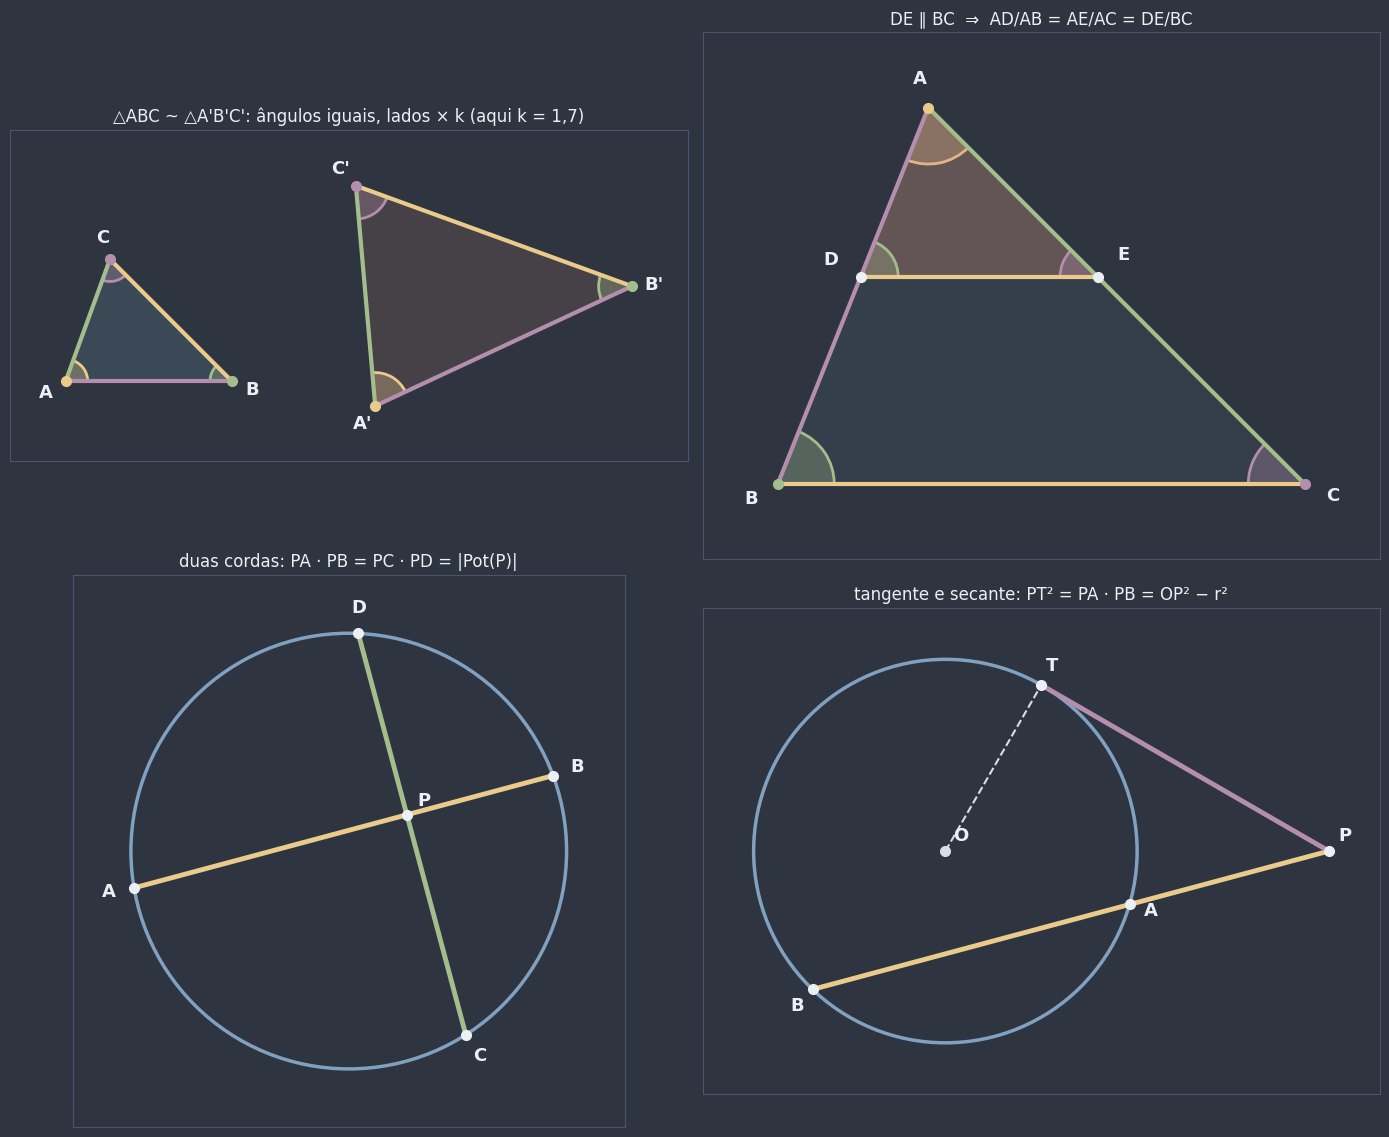

In [20]:
fig, eixos = plt.subplots(2, 2, figsize=(14, 11.5))
fig.patch.set_facecolor(NORD_FUNDO)

# Definição
ax = eixos[0, 0]
t1 = [np.array([0.0, 0.0]), np.array([3.0, 0.0]), np.array([0.8, 2.2])]
t2 = transformar(t1, k=1.7, rotacao=25, destino=(7.0, 1.6))
preparar_eixo(ax, t1 + t2, margem=1.0)
desenhar_triangulo(ax, t1, "ABC", cor_preenchimento=COR_T1, raio_angulo=0.4)
desenhar_triangulo(ax, t2, ("A'", "B'", "C'"), cor_preenchimento=COR_T2, raio_angulo=0.6)
ax.set_title("△ABC ~ △A'B'C': ângulos iguais, lados × k (aqui k = 1,7)", color=NORD_TEXTO, fontsize=12)

# Teorema fundamental
ax = eixos[0, 1]
A_c, B_c, C_c = np.array([2.0, 5.0]), np.array([0.0, 0.0]), np.array([7.0, 0.0])
preparar_eixo(ax, [A_c, B_c, C_c], margem=1.0)
desenhar_fundamental(ax, A_c, B_c, C_c, 0.45, mostrar_F=False)
ax.set_title("DE ∥ BC  ⇒  AD/AB = AE/AC = DE/BC", color=NORD_TEXTO, fontsize=12)

# Duas cordas
ax = eixos[1, 0]
O_c, r_c, P_c = np.array([0.0, 0.0]), 3.0, np.array([0.8, 0.5])
A_c, B_c = intersecoes_reta_circunferencia(O_c, r_c, P_c, 15)
C_c, D_c = intersecoes_reta_circunferencia(O_c, r_c, P_c, 105)
preparar_eixo(ax, [(-3, -3), (3, 3)], margem=0.8)
desenhar_circunferencia(ax, O_c, r_c, cor=COR_CIRCULO)
desenhar_segmento(ax, A_c, B_c, cor=COR_PA_PB, largura=3.5)
desenhar_segmento(ax, C_c, D_c, cor=COR_PC_PD, largura=3.5)
nomear(ax, ((A_c, "A"), (B_c, "B"), (C_c, "C"), (D_c, "D")), O_c, distancia=0.35)
desenhar_ponto(ax, P_c, "P", cor=NORD_TEXTO, deslocamento=(0.15, 0.12))
ax.set_title("duas cordas: PA · PB = PC · PD = |Pot(P)|", color=NORD_TEXTO, fontsize=12)

# Tangente e secante
ax = eixos[1, 1]
P_c = np.array([6.0, 0.0])
T_c, _ = pontos_de_tangencia(O_c, r_c, P_c)
A_c, B_c = intersecoes_reta_circunferencia(O_c, r_c, P_c, 195)
preparar_eixo(ax, [(-3, -3), (6, 3)], margem=0.8)
desenhar_circunferencia(ax, O_c, r_c, cor=COR_CIRCULO)
desenhar_segmento(ax, P_c, B_c, cor=COR_PA_PB, largura=3.5)
desenhar_segmento(ax, P_c, T_c, cor=COR_PT, largura=3.5)
desenhar_segmento(ax, O_c, T_c, cor=NORD_TEXTO_SEC, largura=1.5, estilo="--")
desenhar_ponto(ax, O_c, "O", cor=NORD_TEXTO_SEC)
nomear(ax, ((A_c, "A"), (B_c, "B"), (T_c, "T")), O_c, distancia=0.35)
desenhar_ponto(ax, P_c, "P", cor=NORD_TEXTO, deslocamento=(0.15, 0.15))
ax.set_title("tangente e secante: PT² = PA · PB = OP² − r²", color=NORD_TEXTO, fontsize=12)
plt.tight_layout()
plt.show()

## Exercícios

**Básico**
1. Reconhecer semelhança, usar a razão $k$ e o teorema fundamental.
2. Sombras e potência de ponto com números inteiros.

**Intermediário**

3. Implementar `semelhantes` e `criterios_semelhanca` (e testar com contraexemplos).
4. Potência de ponto verificada com pontos e retas sorteados.
5. Problemas que combinam Tales, semelhança e bissetriz.
6. A demonstração do critério LLL, guiada.

**Desafio**

7. Construindo $\sqrt{a \cdot b}$ com régua e compasso.
8. A altura relativa à hipotenusa.

Gabarito completo com resolução comentada em [`0415b_semelhanca_de_triangulos_e_potencia_de_ponto_gabarito.ipynb`](0415b_semelhanca_de_triangulos_e_potencia_de_ponto_gabarito.ipynb) — tente resolver sozinho antes de olhar.

### Básico

In [ ]:
# Exercício Básico 1: reconhecer semelhança e usar a razão k.
# (a) Os triângulos de lados 3, 4, 5 e 9, 12, 15 são semelhantes? Guarde True ou False em `semelhantes_ex1a`, a
#     razão de semelhança (do menor para o maior) em `k_ex1a` e a razão entre as áreas (maior/menor) em
#     `razao_areas_ex1a`.
# (b) △ABC ~ △DEF, com AB = 6, BC = 8, CA = 10 e DE = 9. Guarde EF em `EF_ex1b` e FD em `FD_ex1b`.
#     (Cuidado com a correspondência: a ordem das letras diz quem corresponde a quem.)
# (c) Um triângulo tem ângulos de 40° e 75°, e outro tem ângulos de 75° e 65°. Guarde em `semelhantes_ex1c` True
#     ou False. Faça o mesmo em `semelhantes_ex1d` para um triângulo com ângulos de 50° e 60° e outro com
#     ângulos de 50° e 80°.
# (e) No triângulo ABC, DE ∥ BC (D em AB, E em AC), AD = 3, DB = 6 e BC = 12. Guarde DE em `DE_ex1e`.
semelhantes_ex1a = ...
k_ex1a = ...
razao_areas_ex1a = ...
EF_ex1b = ...
FD_ex1b = ...
semelhantes_ex1c = ...
semelhantes_ex1d = ...
DE_ex1e = ...

print(semelhantes_ex1a, k_ex1a, razao_areas_ex1a, EF_ex1b, FD_ex1b, semelhantes_ex1c, semelhantes_ex1d, DE_ex1e)

In [ ]:
# Verificação
assert semelhantes_ex1a is not ... and bool(semelhantes_ex1a) and k_ex1a is not ... and math.isclose(k_ex1a, 3), (
    "Tente de novo, revise: 9/3 = 12/4 = 15/5, os lados correspondentes têm a mesma razão (seção 1 - Triângulos semelhantes)."
)
assert razao_areas_ex1a is not ... and math.isclose(razao_areas_ex1a, 9), (
    "Tente de novo, revise: a razão entre as áreas é k², e não k (seção 1 - Triângulos semelhantes)."
)
assert EF_ex1b is not ... and math.isclose(EF_ex1b, 12) and FD_ex1b is not ... and math.isclose(FD_ex1b, 15), (
    "Tente de novo, revise: AB↔DE, BC↔EF, CA↔FD e k = DE/AB = 9/6 (seção 1 - Triângulos semelhantes)."
)
assert semelhantes_ex1c is not ... and bool(semelhantes_ex1c), (
    "Tente de novo, revise: calcule o terceiro ângulo de cada triângulo (soma 180°) e use o critério AA (seção 3 - Critérios de semelhança)."
)
assert semelhantes_ex1d is not ... and not bool(semelhantes_ex1d), (
    "Tente de novo, revise: os ângulos são 50°, 60°, 70° num triângulo e 50°, 80°, 50° no outro; só um ângulo "
    "coincide (seção 3 - Critérios de semelhança)."
)
assert DE_ex1e is not ... and math.isclose(DE_ex1e, 4), (
    "Tente de novo, revise: DE/BC = AD/AB, com o lado INTEIRO AB = 3 + 6 (seção 2 - O teorema fundamental da semelhança)."
)
print("Certo!")

In [ ]:
# Exercício Básico 2: sombras e potência de ponto.
# (a) Uma vara de 1,5 m projeta uma sombra de 2 m. No mesmo instante, um poste projeta uma sombra de 10 m.
#     Guarde a altura do poste em `altura_poste_ex2a`.
# (b) No mesmo instante, uma pessoa de 1,60 m projeta sombra de 1,20 m, e uma árvore projeta sombra de 9 m.
#     Guarde a altura da árvore em `altura_arvore_ex2b`.
# (c) Duas cordas se cortam em P: PA = 4, PB = 6 e PC = 3. Guarde PD em `PD_ex2c`.
# (d) Duas secantes saem de P: na primeira, PA = 4 e PB = 9 (A é o ponto mais próximo); na segunda, PC = 3.
#     Guarde PD em `PD_ex2d` e o comprimento da corda CD em `CD_ex2d`.
# (e) De P saem uma tangente PT e uma secante com PA = 4 e PB = 9. Guarde PT em `PT_ex2e`.
# (f) P está a 10 cm do centro de uma circunferência de raio 6 cm; uma secante por P corta a circunferência a
#     4 cm de P (o ponto mais próximo). Guarde a potência de P em `pot_ex2f` e a distância de P ao outro ponto em
#     `PB_ex2f`.
altura_poste_ex2a = ...
altura_arvore_ex2b = ...
PD_ex2c = ...
PD_ex2d = ...
CD_ex2d = ...
PT_ex2e = ...
pot_ex2f = ...
PB_ex2f = ...

print(altura_poste_ex2a, altura_arvore_ex2b, PD_ex2c, PD_ex2d, CD_ex2d, PT_ex2e, pot_ex2f, PB_ex2f)

In [ ]:
# Verificação
assert altura_poste_ex2a is not ... and math.isclose(altura_poste_ex2a, 7.5), (
    "Tente de novo, revise: altura/sombra é a mesma razão para a vara e para o poste (seção 4 - Aplicações da semelhança)."
)
assert altura_arvore_ex2b is not ... and math.isclose(altura_arvore_ex2b, 12), (
    "Tente de novo, revise: h/9 = 1,60/1,20 (seção 4 - Aplicações da semelhança)."
)
assert PD_ex2c is not ... and math.isclose(PD_ex2c, 8), (
    "Tente de novo, revise: duas cordas, PA · PB = PC · PD (seção 5 - Potência de ponto)."
)
assert PD_ex2d is not ... and math.isclose(PD_ex2d, 12) and CD_ex2d is not ... and math.isclose(CD_ex2d, 9), (
    "Tente de novo, revise: duas secantes, PA · PB = PC · PD, e a corda é CD = PD − PC (seção 5 - Potência de ponto)."
)
assert PT_ex2e is not ... and math.isclose(PT_ex2e, 6), (
    "Tente de novo, revise: PT² = PA · PB, com o segmento inteiro PB (seção 5 - Potência de ponto)."
)
assert pot_ex2f is not ... and math.isclose(pot_ex2f, 64) and PB_ex2f is not ... and math.isclose(PB_ex2f, 16), (
    "Tente de novo, revise: Pot(P) = OP² − r² e PA · PB = Pot(P) (seção 5 - Potência de ponto)."
)
print("Certo!")

### Intermediário

In [ ]:
# Exercício Intermediário 3: implementar os testes de semelhança.
# (a) Complete semelhantes_ex3(t1, t2), que devolve a razão de semelhança k (de t1 para t2) se os triângulos forem
#     semelhantes e None se não forem. Experimente as 6 correspondências (permutations(range(3))) e, em cada uma,
#     confira que os três lados correspondentes têm a mesma razão e que os três ângulos são iguais (use lados,
#     angulos, iguais e math.isclose(..., abs_tol=1e-6)). Não use a função semelhantes do notebook.
# (b) Complete criterios_ex3(t1, t2), que devolve a lista (na ordem "AA", "LAL", "LLL") dos critérios satisfeitos
#     com a correspondência dada pela ORDEM dos vértices (t1[i] ↔ t2[i]). Lembre: lados(t)[i] é o lado oposto ao
#     vértice i, e no LAL o ângulo tem de estar ENTRE os dois lados. Não use criterios_semelhanca.
# (c) Guarde em `criterios_lla_ex3` o resultado de criterios_ex3 para o contraexemplo LLA da seção 3:
#     t1 = [A_lla, B_lla, C1_lla] e t2 = transformar([A_lla, B_lla, C2_lla], k=1.5).


def semelhantes_ex3(t1, t2):
    ...


def criterios_ex3(t1, t2) -> list:
    ...


criterios_lla_ex3 = ...

print(semelhantes_ex3(triangulo_por_lados(3, 4, 5), triangulo_por_lados(12, 9, 15)), criterios_lla_ex3)

In [ ]:
# Verificação
gerador_ex3 = np.random.default_rng(3)
testados = 0
while testados < 60:
    t_base = list(gerador_ex3.uniform(-5, 5, (3, 2)))
    if area_triangulo(t_base) < 2:
        continue  # descarta triângulos quase "achatados"
    testados += 1
    k_t = float(gerador_ex3.uniform(0.3, 3))
    copia = transformar(t_base, k=k_t, rotacao=float(gerador_ex3.uniform(0, 360)), refletir=bool(testados % 2))
    embaralhada = [copia[i] for i in gerador_ex3.permutation(3)]
    k_obtido = semelhantes_ex3(t_base, embaralhada)
    assert k_obtido is not None and math.isclose(k_obtido, k_t, rel_tol=1e-6), (
        "Tente de novo, revise: com os vértices embaralhados, é preciso testar as 6 correspondências (seção 1 - Triângulos semelhantes)."
    )
    deformado = [p.copy() for p in copia]
    deformado[0] = deformado[0] + gerador_ex3.uniform(0.5, 1.5, 2)
    assert semelhantes_ex3(t_base, deformado) is None, (
        "Tente de novo, revise: devolva None quando nenhuma correspondência funciona (seção 1 - Triângulos semelhantes)."
    )
    assert criterios_ex3(t_base, copia) == criterios_semelhanca(t_base, copia) == ["AA", "LAL", "LLL"], (
        "Tente de novo, revise: um par semelhante (na ordem certa) satisfaz os três critérios (seção 3 - Critérios de semelhança)."
    )
    assert criterios_ex3(t_base, deformado) == criterios_semelhanca(t_base, deformado), (
        "Tente de novo, revise: compare cada ângulo com o seu correspondente e cada lado com o seu (seção 3 - Critérios de semelhança)."
    )
assert criterios_lla_ex3 is not ... and list(criterios_lla_ex3) == [], (
    "Tente de novo, revise: no LLA o ângulo NÃO está entre os lados proporcionais, então não é LAL (seção 3 - Critérios de semelhança)."
)
print("Certo!")

In [ ]:
# Exercício Intermediário 4: a potência de ponto conferida com sorteios.
# (a) Complete potencia_ex4(O, r, P), que devolve OP² − r². (Não use potencia.)
# (b) Complete produto_ex4(O, r, P, angulo), que devolve PA · PB para a reta que passa por P na direção `angulo`
#     (use intersecoes_reta_circunferencia) ou None se a reta não cortar a circunferência em dois pontos.
# (c) Com gerador_ex4 = np.random.default_rng(15), faça 300 sorteios: O = gerador_ex4.uniform(-3, 3, 2),
#     r = gerador_ex4.uniform(1, 4), P = gerador_ex4.uniform(-8, 8, 2) e angulo = gerador_ex4.uniform(0, 180),
#     NESSA ordem. Ignore os sorteios em que produto_ex4 der None. Guarde em `testes_ex4` quantos sorteios foram
#     usados e em `maior_erro_ex4` o maior valor de |PA·PB − |Pot(P)||.
# (d) Nos sorteios usados com P exterior, calcule também PT² (use pontos_de_tangencia) e guarde em
#     `maior_erro_tangente_ex4` o maior valor de |PT² − Pot(P)|.


def potencia_ex4(O, r: float, P) -> float:
    ...


def produto_ex4(O, r: float, P, angulo: float):
    ...


testes_ex4 = ...
maior_erro_ex4 = ...
maior_erro_tangente_ex4 = ...

print(testes_ex4, maior_erro_ex4, maior_erro_tangente_ex4)

In [ ]:
# Verificação
for O_t, r_t, P_t, pot_certa in [((0, 0), 5, (8, 6), 75), ((1, 1), 2, (1, 2), -3), ((0, 0), 3, (3, 0), 0)]:
    assert potencia_ex4(O_t, r_t, P_t) is not None and math.isclose(potencia_ex4(O_t, r_t, P_t), pot_certa,
                                                                    abs_tol=1e-9), (
        f"Tente de novo, revise: com O = {O_t}, r = {r_t} e P = {P_t}, OP² − r² = {pot_certa} (seção 5 - Potência de ponto)."
    )
assert produto_ex4((0, 0), 5, (3, 0), 90) is not None and math.isclose(produto_ex4((0, 0), 5, (3, 0), 90), 16), (
    "Tente de novo, revise: a reta vertical por P = (3, 0) corta a circunferência em (3, ±4): PA · PB = 4 · 4 "
    "(seção 5 - Potência de ponto)."
)
assert produto_ex4((0, 0), 1, (5, 0), 90) is None, (
    "Tente de novo, revise: devolva None quando a reta não corta a circunferência em dois pontos (seção 5 - Potência de ponto)."
)
assert testes_ex4 is not ... and 50 <= testes_ex4 <= 300, (
    "Tente de novo, revise: conte só os sorteios em que a reta corta a circunferência (seção 5 - Potência de ponto)."
)
assert maior_erro_ex4 is not ... and maior_erro_ex4 < 1e-8, (
    "Tente de novo, revise: compare PA · PB com o VALOR ABSOLUTO da potência (seção 5 - Potência de ponto)."
)
assert maior_erro_tangente_ex4 is not ... and maior_erro_tangente_ex4 < 1e-8, (
    "Tente de novo, revise: PT² = Pot(P) para P exterior, com T = pontos_de_tangencia(O, r, P)[0] (seção 5 - Potência de ponto)."
)
print("Certo!")

In [ ]:
# Exercício Intermediário 5: Tales, semelhança e bissetriz juntos. No triângulo ABC, AB = 9, AC = 6 e BC = 10.
# (a) A bissetriz interna de A corta BC em D. Guarde BD em `BD_ex5` e DC em `DC_ex5` (teorema da bissetriz, 0414a).
# (b) Por D, traça-se a paralela ao lado AC, que corta AB em F. O triângulo BDF é semelhante a BCA (teorema
#     fundamental). Guarde a razão de semelhança k = BD/BC em `k_ex5`, BF em `BF_ex5` e DF em `DF_ex5`.
# (c) Guarde em `razao_areas_ex5` a razão área(BDF)/área(BCA).
# (d) Outro triângulo: DE ∥ BC, com D em AB, AD = x, DB = 4, DE = 6 e BC = 10. Guarde x em `x_ex5d`.
BD_ex5 = ...
DC_ex5 = ...
k_ex5 = ...
BF_ex5 = ...
DF_ex5 = ...
razao_areas_ex5 = ...
x_ex5d = ...

print(BD_ex5, DC_ex5, k_ex5, BF_ex5, DF_ex5, razao_areas_ex5, x_ex5d)

In [ ]:
# Verificação
assert BD_ex5 is not ... and math.isclose(BD_ex5, 6) and DC_ex5 is not ... and math.isclose(DC_ex5, 4), (
    "Tente de novo, revise: BD/DC = AB/AC = 9/6 e BD + DC = 10, pelo teorema da bissetriz (0414a, seção 5 - "
    "Teorema da bissetriz interna e externa)."
)
assert k_ex5 is not ... and math.isclose(k_ex5, 0.6), (
    "Tente de novo, revise: no triângulo BCA, DF ∥ CA; a razão é BD/BC = 6/10 (seção 2 - O teorema fundamental da semelhança)."
)
assert BF_ex5 is not ... and math.isclose(BF_ex5, 5.4) and DF_ex5 is not ... and math.isclose(DF_ex5, 3.6), (
    "Tente de novo, revise: BF/BA = DF/CA = k, com BA = 9 e CA = 6 (seção 2 - O teorema fundamental da semelhança)."
)
assert razao_areas_ex5 is not ... and math.isclose(razao_areas_ex5, 0.36), (
    "Tente de novo, revise: a razão entre as áreas é k² (seção 1 - Triângulos semelhantes)."
)
assert x_ex5d is not ... and math.isclose(x_ex5d, 6), (
    "Tente de novo, revise: AD/AB = DE/BC, ou seja, x/(x + 4) = 6/10 (seção 2 - O teorema fundamental da semelhança)."
)
print("Certo!")

In [ ]:
# Exercício Intermediário 6: a demonstração do critério LLL, guiada.
# Hipótese: A'B'/AB = B'C'/BC = C'A'/CA = k < 1. Construção: D em AB com AD = A'B' e E em AC com AE = A'C'.
#   Passo 1. AD/AB = AE/AC = k                       justificativa: ?
#   Passo 2. DE ∥ BC                                 justificativa: ?
#   Passo 3. △ADE ~ △ABC, logo DE = k · BC = B'C'    justificativa: ?
#   Passo 4. △ADE ≡ △A'B'C'                          justificativa: ?
#   Passo 5. △A'B'C' ~ △ABC                          (passos 3 e 4: A'B'C' é uma cópia exata de ADE)
# Menu de justificativas:
#   "a" recíproca de Tales no triângulo (0414a)       "b" teorema fundamental da semelhança (seção 2)
#   "c" caso LLL de congruência (0405a)               "d" a construção de D e E, junto com a hipótese
#   "e" caso LAL de congruência (0405a)               "f" ângulos correspondentes entre paralelas (0406a)
# (a) Guarde em `justificativas_ex6` a lista das letras dos passos 1, 2, 3 e 4, nessa ordem.
# (b) Confira a cadeia em código, com ABC = (0, 0), (10, 0), (3, 6) e A'B'C' = triangulo_por_lados(k·a, k·b, k·c)
#     para k = 0,6 (em que a, b, c = lados(ABC)). Calcule D e E pela construção e guarde:
#     - em `paralelo_ex6`, o resultado de sao_paralelos(D, E, B, C);
#     - em `DE_ex6` a medida de DE e em `B2C2_ex6` a medida de B'C';
#     - em `angulos_iguais_ex6`, True se os ângulos de ADE forem (com math.isclose) os de A'B'C', na ordem.
A_ex6, B_ex6, C_ex6 = np.array([0.0, 0.0]), np.array([10.0, 0.0]), np.array([3.0, 6.0])
k_ex6 = 0.6

justificativas_ex6 = ...
paralelo_ex6 = ...
DE_ex6 = ...
B2C2_ex6 = ...
angulos_iguais_ex6 = ...

print(justificativas_ex6, paralelo_ex6, DE_ex6, B2C2_ex6, angulos_iguais_ex6)

In [ ]:
# Verificação
assert justificativas_ex6 is not ... and len(justificativas_ex6) == 4, (
    "Tente de novo, revise: são quatro letras, uma para cada um dos passos 1 a 4 (seção 3 - Critérios de semelhança)."
)
assert justificativas_ex6[0] == "d", (
    "Tente de novo, revise: o passo 1 vem de AD = A'B', AE = A'C' e da hipótese A'B'/AB = A'C'/AC = k (seção 3 - Critérios de semelhança)."
)
assert justificativas_ex6[1] == "a", (
    "Tente de novo, revise: razões iguais nos dois lados ⇒ paralela ao terceiro lado é a RECÍPROCA de Tales (seção 3 - Critérios de semelhança)."
)
assert justificativas_ex6[2] == "b", (
    "Tente de novo, revise: com DE ∥ BC, quem dá a semelhança (e DE/BC = k) é o teorema fundamental (seção 2 - O teorema fundamental da semelhança)."
)
assert justificativas_ex6[3] == "c", (
    "Tente de novo, revise: AD = A'B', AE = A'C' e DE = B'C': três lados iguais, caso LLL de congruência (seção 3 - Critérios de semelhança)."
)
assert paralelo_ex6 is not ... and bool(paralelo_ex6), (
    "Tente de novo, revise: D = A + (A'B'/AB)·(B − A) e E = A + (A'C'/AC)·(C − A) (seção 3 - Critérios de semelhança)."
)
assert DE_ex6 is not ... and B2C2_ex6 is not ... and math.isclose(DE_ex6, B2C2_ex6) and \
    math.isclose(DE_ex6, 0.6 * math.dist(B_ex6, C_ex6)), (
    "Tente de novo, revise: DE = k · BC = B'C' (seção 2 - O teorema fundamental da semelhança)."
)
assert angulos_iguais_ex6 is not ... and bool(angulos_iguais_ex6), (
    "Tente de novo, revise: compare angulos([A, D, E]) com angulos(A'B'C'), na ordem (seção 3 - Critérios de semelhança)."
)
print("Certo!")

### Desafio

In [ ]:
# Exercício Desafio 7: construindo √(a·b) com régua e compasso.
# Sobre uma reta, marque A, P e B, com P entre A e B, PA = a e PB = b. Trace a circunferência de diâmetro AB e,
# por P, a perpendicular a AB, que corta a circunferência em Q1 e Q2. Afirmação: PQ1 = √(a·b).
# (a) Complete media_geometrica_ex7(a, b), que faz a construção em coordenadas e devolve a medida PQ1:
#     P = (0, 0), A = (−a, 0), B = (b, 0); o centro é o ponto médio de AB e o raio é (a + b)/2; use
#     intersecoes_reta_circunferencia com a direção 90° (a perpendicular a AB por P).
# (b) Para os pares (1, 4), (2, 8), (3, 12), (2, 3) e (5, 7.2), guarde em `resultados_ex7` a lista das medidas
#     construídas e em `maior_erro_ex7` o maior valor de |medida − √(a·b)|.
# (c) Para a = 2 e b = 8, com g = media_geometrica_ex7(2, 8), guarde em `razoes_pg_ex7` a tupla (g/a, b/g).
#     Se forem iguais, a, g, b formam uma PG (0303a).
# (d) (Para pensar, sem assert) Por que funciona? Use as duas cordas (AB e Q1Q2) que se cortam em P e lembre que
#     o diâmetro perpendicular a uma corda passa pelo ponto médio dela (0412a).


def media_geometrica_ex7(a: float, b: float) -> float:
    ...


resultados_ex7 = ...
maior_erro_ex7 = ...
razoes_pg_ex7 = ...

print(resultados_ex7, maior_erro_ex7, razoes_pg_ex7)

In [ ]:
# Verificação
for a_t, b_t in [(1, 9), (4, 4), (0.5, 8), (7, 3)]:
    g_t = media_geometrica_ex7(a_t, b_t)
    assert g_t is not None and math.isclose(g_t, math.sqrt(a_t * b_t)), (
        f"Tente de novo, revise: com a = {a_t} e b = {b_t}, a construção deveria dar √(a·b) = "
        f"{math.sqrt(a_t * b_t):.4f}; use o centro (b − a)/2 e o raio (a + b)/2 (seção 5 - Potência de ponto)."
    )
assert resultados_ex7 is not ... and len(resultados_ex7) == 5, (
    "Tente de novo, revise: uma medida para cada um dos cinco pares (seção 5 - Potência de ponto)."
)
assert maior_erro_ex7 is not ... and maior_erro_ex7 < 1e-9, (
    "Tente de novo, revise: compare cada medida com math.sqrt(a * b) (seção 5 - Potência de ponto)."
)
assert razoes_pg_ex7 is not ... and math.isclose(razoes_pg_ex7[0], 2) and math.isclose(razoes_pg_ex7[1], 2), (
    "Tente de novo, revise: g = √(2·8) = 4, e 4/2 = 8/4 = 2 (seção 5 - Potência de ponto)."
)
print("Certo!")

In [ ]:
# Exercício Desafio 8: a altura relativa à hipotenusa.
# O triângulo ABC tem ângulo reto em A: B = (0, 0), C = (13, 0) e A = (4, 6).
# (a) Calcule o pé H da altura relativa à hipotenusa BC: a projeção ortogonal de A sobre a reta BC (0407a),
#     H = B + ((A − B)·(C − B) / |C − B|²)·(C − B). Guarde H em `H_ex8`, a altura h = AH em `h_ex8` e as projeções
#     m = BH e n = HC em `m_ex8` e `n_ex8`.
# (b) Guarde em `hh_mn_ex8` a tupla (h², m·n).
# (c) Guarde em `criterios_ex8` a tupla (criterios_semelhanca(ABC, HBA), criterios_semelhanca(ABC, HAC)),
#     com os vértices listados nessa ordem (A↔H, B↔B, C↔A no primeiro par; A↔H, B↔A, C↔C no segundo).
# (d) A potência de ponto: O é o ponto médio de BC e r = BC/2 (A está nessa circunferência, 0413a). Guarde em
#     `pot_H_ex8` a potência de H e em `pot_A_ex8` a potência de A.
# (e) Sorteie 50 triângulos retângulos com gerador_ex8 = np.random.default_rng(8): para cada um, B = (0, 0),
#     C = (L, 0) com L = gerador_ex8.uniform(2, 20) e A = (L/2, 0) + (L/2)·direcao(θ), com
#     θ = gerador_ex8.uniform(10, 170) (sorteie L e θ nessa ordem). Guarde em `maior_erro_ex8` o maior |h² − m·n|.
A_ex8, B_ex8, C_ex8 = np.array([4.0, 6.0]), np.array([0.0, 0.0]), np.array([13.0, 0.0])

H_ex8 = ...
h_ex8 = ...
m_ex8 = ...
n_ex8 = ...
hh_mn_ex8 = ...
criterios_ex8 = ...
pot_H_ex8 = ...
pot_A_ex8 = ...
maior_erro_ex8 = ...

print(H_ex8, h_ex8, m_ex8, n_ex8, hh_mn_ex8, criterios_ex8, pot_H_ex8, pot_A_ex8, maior_erro_ex8)

In [ ]:
# Verificação
assert H_ex8 is not ... and np.allclose(H_ex8, (4, 0)), (
    "Tente de novo, revise: H é a projeção ortogonal de A sobre a reta BC, como em 0407a (seção 4 - Aplicações da semelhança)."
)
assert h_ex8 is not ... and math.isclose(h_ex8, 6) and m_ex8 is not ... and math.isclose(m_ex8, 4) and \
    n_ex8 is not ... and math.isclose(n_ex8, 9), (
    "Tente de novo, revise: h = AH, m = BH e n = HC, medidos com math.dist (seção 4 - Aplicações da semelhança)."
)
assert hh_mn_ex8 is not ... and math.isclose(hh_mn_ex8[0], 36) and math.isclose(hh_mn_ex8[1], 36), (
    "Tente de novo, revise: h² = 36 e m · n = 4 · 9 (seção 4 - Aplicações da semelhança)."
)
assert criterios_ex8 is not ... and [list(c) for c in criterios_ex8] == [["AA", "LAL", "LLL"]] * 2, (
    "Tente de novo, revise: liste os vértices na ordem da correspondência, [H, B, A] e [H, A, C] (seção 4 - Aplicações da semelhança)."
)
assert pot_H_ex8 is not ... and math.isclose(pot_H_ex8, -36), (
    "Tente de novo, revise: Pot(H) = OH² − r², com O = (6,5; 0) e r = 6,5; deve dar −m·n (seção 5 - Potência de ponto)."
)
assert pot_A_ex8 is not ... and math.isclose(pot_A_ex8, 0, abs_tol=1e-9), (
    "Tente de novo, revise: A está sobre a circunferência de diâmetro BC, então a potência é zero (seção 5 - Potência de ponto)."
)
assert maior_erro_ex8 is not ... and maior_erro_ex8 < 1e-8, (
    "Tente de novo, revise: para cada triângulo, calcule H, h, m e n e guarde o maior |h² − m·n| (seção 4 - Aplicações da semelhança)."
)
print("Certo!")

## Conexões

**Isso depende de:**
- [`0402a_segmento_de_reta.ipynb`](0402a_segmento_de_reta.ipynb) (razão entre segmentos)
- [`0404a_triangulos_conceito_elementos_e_classificacao.ipynb`](0404a_triangulos_conceito_elementos_e_classificacao.ipynb) (soma dos ângulos internos, usada no critério AA, e "ao maior lado opõe-se o maior ângulo", que organiza a correspondência)
- [`0405a_congruencia_de_triangulos.ipynb`](0405a_congruencia_de_triangulos.ipynb) (casos LAL, ALA e LLL de congruência, peças das demonstrações dos três critérios, e o contraste com o "falso caso" AAA)
- [`0406a_paralelismo.ipynb`](0406a_paralelismo.ipynb) (ângulos correspondentes entre paralelas, no teorema fundamental e na construção do critério AA)
- [`0412a_circunferencia_e_circulo.ipynb`](0412a_circunferencia_e_circulo.ipynb) (corda, secante, tangente perpendicular ao raio e pontos de tangência)
- [`0413a_angulos_na_circunferencia.ipynb`](0413a_angulos_na_circunferencia.ipynb) (ângulo inscrito e ângulo de segmento, que fornecem o segundo ângulo do critério AA nas três relações de potência)
- [`0414a_teorema_de_tales.ipynb`](0414a_teorema_de_tales.ipynb) (Tales no triângulo e a sua recíproca, o motor das demonstrações; aqui foi cumprida a promessa da razão $\frac{DE}{BC} = \frac{AD}{AB}$)
- Referências cruzadas: [`0408a_quadrilateros_definicao_elementos_e_trapezios.ipynb`](0408a_quadrilateros_definicao_elementos_e_trapezios.ipynb) e [`0409a_paralelogramos_e_casos_particulares.ipynb`](0409a_paralelogramos_e_casos_particulares.ipynb) (base média e paralelogramo, no teorema fundamental), [`0109a_funcao_quadratica_sinal_inequacoes_e_raizes.ipynb`](../01_conjuntos_e_funcoes/0109a_funcao_quadratica_sinal_inequacoes_e_raizes.ipynb) (soma e produto das raízes, a demonstração algébrica da potência) e [`0303a_progressao_geometrica.ipynb`](../03_progressoes_matrizes_e_sistemas_lineares/0303a_progressao_geometrica.ipynb) (média geométrica, no Desafio 7)

**Isso será usado em:**
- [`0416a_triangulos_retangulos.ipynb`](0416a_triangulos_retangulos.ipynb) (todas as relações métricas saem da semelhança dos três triângulos formados pela altura relativa à hipotenusa e da potência de ponto; o Teorema de Pitágoras)
- [`0417a_triangulos_quaisquer.ipynb`](0417a_triangulos_quaisquer.ipynb) (cálculo de alturas, medianas e bissetrizes, que usam semelhança e potência de ponto)
- [`0418a_poligonos_regulares_e_comprimento_da_circunferencia.ipynb`](0418a_poligonos_regulares_e_comprimento_da_circunferencia.ipynb) (dois polígonos regulares com o mesmo número de lados são semelhantes)
- 📌 Equivalência Plana e 📌 Áreas de Superfícies Planas (a razão entre as áreas de figuras semelhantes é $k^2$)
- [`0509a_triangulos_retangulos.ipynb`](../05_trigonometria/0509a_triangulos_retangulos.ipynb) e o restante da Trigonometria: seno, cosseno e tangente são consequência da semelhança de triângulos retângulos